<a href="https://colab.research.google.com/github/zuvelatamara/PPPO-2025/blob/main/PPPO_V5_Case_study_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Case study 1: Detekcija i klasifikacija lica**



##  Instalacija biblioteka



In [1]:
# Instalacija MediaPipe-a i MTCNN-a (TensorFlow i ostalo već postoje u Colab-u)
!pip install -q mediapipe mtcnn lz4

# Ostavljamo samo jedan OpenCV paket, verzije 4 (u OpenCV 5 nema Haar detektora - CascadeClassifier)
!pip uninstall -y -q opencv-python opencv-python-headless opencv-contrib-python-headless
!pip install -q "opencv-contrib-python>=4.10,<5"

# Preuzimanje MediaPipe modela za detekciju lica (kratki domet, lica do ~2 m od kamere)
!wget -q -O blaze_face_short_range.tflite https://storage.googleapis.com/mediapipe-models/face_detector/blaze_face_short_range/float16/latest/blaze_face_short_range.tflite
!ls -lh blaze_face_short_range.tflite

#POSLE OVE ĆELIJE: Runtime → Restart session, pa nastaviti od sledeće ćelije

-rw-r--r-- 1 root root 225K Apr 26  2023 blaze_face_short_range.tflite


# **Face detection / Detekcija lica**

### **Uvod**

Prepoznavanje i detekcija lica predstavljaju jedan od najvećih izazova u oblasti računarskog vida u prethodnim decenijama. Ovaj problem nije bio rešiv klasičnim skupom računarskih instrukcija, već je njegov razvoj uslovio pojavu i intenzivnu primenu tehnika mašinskog učenja. U početku su sistemi za obradu lica korišćeni isključivo u akademskim i istraživačkim okruženjima, dok danas imaju široku primenu u različitim oblastima, kao što su mobilni uređaji, bezbednosni sistemi, robotika i interfejsi između čoveka i računara.

Pouzdanost i tačnost sistema za obradu lica zavise od više faktora, među kojima su kvalitet ulazne slike, raspoloživa računarska snaga i vrsta modela mašinskog učenja koji se koristi. Jedan od glavnih problema u ranim fazama razvoja ovih sistema bio je nedostatak velikih i raznovrsnih skupova podataka. Sa pojavom otvorenih skupova podataka koji sadrže i po nekoliko miliona slika lica, omogućeno je treniranje znatno robusnijih i preciznijih modela, što je dovelo do značajnog napretka u ovoj oblasti.

Danas je detekcija lica prvi i nezaobilazni korak u brojnim sistemima, kao što su prepoznavanje lica, video-nadzor, prepoznavanje izraza lica, interfejsi između čoveka i računara, kao i automatizovano formiranje baza podataka lica. Detekcija lica podrazumeva lokalizaciju lica na slici i određivanje njegovih granica, dok se sam proces prepoznavanja lica nadovezuje na detekciju i odnosi se na identifikaciju ili upoređivanje detektovanih lica sa postojećim uzorcima u bazi podataka.

Savremeni digitalni fotoaparati koriste detekciju lica za potrebe automatskog fokusiranja, dok društvene mreže i softveri za organizaciju fotografija omogućavaju automatsko obeležavanje lica na slikama. Jednom označeno lice može se kasnije koristiti za prepoznavanje iste osobe na drugim fotografijama. Takođe, u kombinaciji sa prepoznavanjem gestikulacije, detekcija lica se koristi i u sistemima za interakciju između čoveka i računara.

Postoji veliki broj algoritama za detekciju lica, koji se u literaturi najčešće svrstavaju u sledeće četiri kategorije:

- algoritmi zasnovani na znanju,

- algoritmi zasnovani na nepromenljivim karakteristikama lica,

- algoritmi zasnovani na poklapanju šablona i

- algoritmi zasnovani na izgledu.

**Algoritmi zasnovani na znanju** koriste unapred definisana pravila koja opisuju karakteristike ljudskog lica, kao što su simetrija, prisustvo očiju, nosa i usta, kao i njihovi međusobni odnosi. Ova pravila mogu biti jednostavna ili dobijena eksperimentalno na osnovu velikog broja slika. Nedostatak ovih algoritama ogleda se u teškoći formalizacije ljudskog znanja i kompromisu između broja lažno pozitivnih i lažno negativnih detekcija.

**Algoritmi zasnovani na nepromenljivim karakteristikama lica** polaze od pretpostavke da određene crte lica ostaju relativno stabilne bez obzira na promene poze i osvetljenja. Ovi algoritmi često izdvajaju oči, obrve, nos i usta, ili koriste teksturalne karakteristike kože i kose. Prepoznavanje boje kože se takođe koristi kao dopunska tehnika, često u kombinaciji sa drugim metodama.

**Algoritmi zasnovani na poklapanju šablona** koriste unapred definisane ili statistički formirane šablone koji opisuju izgled lica. Detekcija se zasniva na poređenju delova slike sa pripremljenim šablonima. Glavni izazov ovih metoda je osetljivost na promene u veličini, položaju i pozi lica, zbog čega se često koristi više šablona za različite situacije.

**Algoritmi zasnovani na izgledu** predstavljaju savremeni pristup koji se oslanja na statističku analizu i mašinsko učenje. Ovi algoritmi koriste veliki broj slika sa i bez lica kako bi naučili karakteristične obrasce, na osnovu kojih se sa određenom verovatnoćom vrši detekcija lica. Upravo ova grupa algoritama predstavlja osnovu modernih sistema za detekciju lica zasnovanih na dubokom učenju.

Važno je napomenuti da navedene kategorije nisu strogo razdvojene i da mnogi savremeni algoritmi kombinuju više pristupa. U praksi se za detekciju lica koriste različite metode, poput Haarovih kaskada (Viola–Jones), histograma orijentisanih gradijenata (HOG), metoda potpornih vektora (SVM), kao i metoda dubokog učenja.

U okviru ovog case study projekta fokus je stavljen isključivo na problem detekcije lica, sa ciljem upoređivanja različitih algoritamskih pristupa i analize njihovih prednosti i ograničenja na realnom skupu podataka.

## 1. Analiza dataset-a

U ovom delu projekta analiziramo dataset koji će se koristiti u nastavku. Cilj je da razumemo:
- kako su podaci organizovani (struktura foldera),
- koliko slika postoji po klasi,
- kakav je vizuelni kvalitet slika (osvetljenje, poza, pozadina),
- koja ograničenja dataset-a mogu uticati na rezultate detekcije.

Napomena: slike u ovom dataset-u su već kropovane (isečene) tako da lice zauzima centralni deo kadra. Zbog toga je problem detekcije lica pojednostavljen u odnosu na realne scenarije, ali dataset je odličan za demonstraciju i poređenje različitih metoda detekcije.


**O podacima:**

- Dataset se sastoji od ukupno 274 slike podeljene u 5 foldera (po jednoj osobi / liku).
Slike su organizovane kao podfolderi, pri čemu svaki folder sadrži slike lica jednog Avengers lika:

    1. Chris Evans (**Captain America**) - 50 fotografija

    2. Chris Hemsworth (**Thor**) - 53 fotografije

    3. Mark Ruffalo (**Hulk**) - 66 fotografija

    4. Robert DowneyJr (**The Iron man**) - 51 fotografija

    5. Scarlett Johansson (**Black Widow**) - 54 fotografije

Dataset je dostupan u Google Drive folderu:

 - **Ceo link do foldera sa datasetom:** https://drive.google.com/file/d/1tMVPAJYk1wILu9qxH-XfHBVK_d2sERad/view?usp=sharing

 - **ID fajla:** 1tMVPAJYk1wILu9qxH-XfHBVK_d2sERad

In [2]:
# Učitavanje dataseta
!pip install gdown
import gdown

file_id = "1tMVPAJYk1wILu9qxH-XfHBVK_d2sERad"
gdown.download(f"https://drive.google.com/uc?id={file_id}", output="images.zip", quiet=False)

!unzip -q -o images.zip

Downloading...
From (original): https://drive.google.com/uc?id=1tMVPAJYk1wILu9qxH-XfHBVK_d2sERad
From (redirected): https://drive.google.com/uc?id=1tMVPAJYk1wILu9qxH-XfHBVK_d2sERad&confirm=t&uuid=beb9ccc8-4d13-49de-936c-a62784bfab7b
To: /content/images.zip
100%|██████████| 57.2M/57.2M [00:00<00:00, 163MB/s]


In [3]:
import os

DATASET_PATH = "cropped_images"

folders = os.listdir(DATASET_PATH)
folders


['scarlett_johansson',
 'mark_ruffalo',
 'chris_evans',
 'chris_hemsworth',
 'robert_downey_jr']

### Broj slika po klasi

Sledeća analiza prikazuje koliko slika postoji u svakoj klasi (folderu). Ovaj korak je važan jer:
- dataset može biti nebalansiran (neke klase imaju više slika),
- mali dataset može uticati na kvalitet modela koji se trenira,
- za detekciju balans nije presudan, ali je korisno razumeti strukturu podataka.


In [4]:
total_images = 0

print("Broj slika po klasi:\n")

for folder in folders:
    folder_path = os.path.join(DATASET_PATH, folder)
    images = os.listdir(folder_path)
    print(f"{folder}: {len(images)} slika")
    total_images += len(images)

print(f"\nUkupan broj slika u dataset-u: {total_images}")


Broj slika po klasi:

scarlett_johansson: 54 slika
mark_ruffalo: 66 slika
chris_evans: 50 slika
chris_hemsworth: 53 slika
robert_downey_jr: 51 slika

Ukupan broj slika u dataset-u: 274


### Vizuelni pregled dataset-a

Pre nego što primenimo bilo kakve algoritme, potrebno je vizuelno proveriti slike.
Ovaj korak pomaže da uočimo:
- osvetljenje (dan/noć, senke),
- položaj i rotaciju lica (frontalno/profil),
- prisustvo pozadine i šuma,
- da li su slike konzistentne po veličini i kvalitetu.

Na osnovu ovoga možemo bolje razumeti gde bi algoritmi mogli da greše.


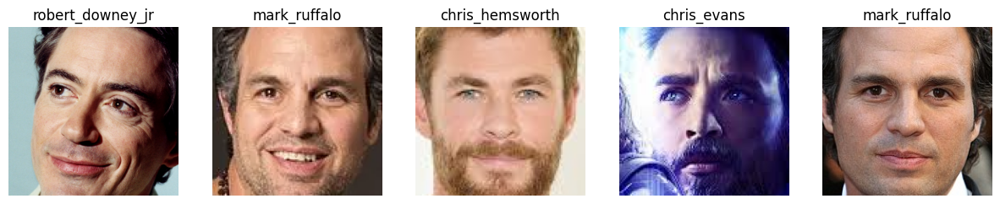

In [5]:
import cv2
import matplotlib.pyplot as plt
import random

def prikazi_nasumicne_slike(dataset_path, n=5):
    plt.figure(figsize=(15,4))

    for i in range(n):
        folder = random.choice(folders)
        img_name = random.choice(os.listdir(os.path.join(dataset_path, folder)))
        img_path = os.path.join(dataset_path, folder, img_name)

        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        plt.subplot(1, n, i+1)
        plt.imshow(img)
        plt.title(folder)
        plt.axis("off")

    plt.show()

prikazi_nasumicne_slike(DATASET_PATH)


### Zaključak analize dataset-a

Na osnovu prethodnih koraka može se zaključiti sledeće:

- Dataset je organizovan po klasama (svaka osoba je poseban folder).
- Broj slika po klasi je približno sličan, ali nije nužno potpuno izbalansiran.
- Slike su kropovane, što znači da lice uglavnom zauzima centralni deo kadra.
- Ipak, dataset je vrlo pogodan za demonstraciju i poređenje algoritama za detekciju lica, kao i za izgradnju jednostavnog klasifikacionog modela (u drugom delu projekta).


## 2. Predprocesiranje

U ovom projektu predprocesiranje ima dve uloge:

1) **Za detekciju lica (Čas 1)**  
   - često se koristi slika u sivim tonovima (npr. Haar cascade),
   - ponekad se radi smanjenje slike radi bržeg izvršavanja.

2) **Za klasifikaciju (Čas 2)**  
   - slike se dovode na istu veličinu (npr. 224×224),
   - vrši se normalizacija piksela,
   - opciono se koriste augmentacije (rotacija, zoom, flip).

U nastavku definišemo osnovne funkcije koje će se koristiti u oba dela projekta.


In [6]:
#Osnovne helper funkcije

import numpy as np

def load_image_rgb(img_path):
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        raise FileNotFoundError(f"Ne mogu da učitam sliku: {img_path}")
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

def resize_image(img_rgb, size=(224, 224)):
    return cv2.resize(img_rgb, size)

def to_grayscale(img_rgb):
    return cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

def normalize_01(img_rgb):
    return img_rgb.astype(np.float32) / 255.0


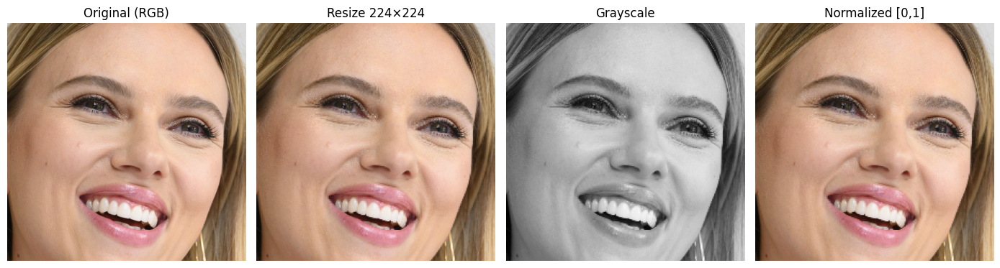

In [7]:
# Demonstracija predprocesiranja na jednoj slici
sample_folder = folders[0]
sample_img = sorted([f for f in os.listdir(os.path.join(DATASET_PATH, sample_folder))
                     if f.lower().endswith((".png", ".jpg", ".jpeg"))])[0]
img_path = os.path.join(DATASET_PATH, sample_folder, sample_img)

img_rgb = load_image_rgb(img_path)
img_resized = resize_image(img_rgb, (224, 224))
img_gray = to_grayscale(img_resized)
img_norm = normalize_01(img_resized)

plt.figure(figsize=(14,4))
plt.subplot(1,4,1); plt.imshow(img_rgb); plt.title("Original (RGB)"); plt.axis("off")
plt.subplot(1,4,2); plt.imshow(img_resized); plt.title("Resize 224×224"); plt.axis("off")
plt.subplot(1,4,3); plt.imshow(img_gray, cmap="gray"); plt.title("Grayscale"); plt.axis("off")
plt.subplot(1,4,4); plt.imshow(img_norm); plt.title("Normalized [0,1]"); plt.axis("off")
plt.tight_layout()
plt.show()


### Zaključak predprocesiranja

U ovom projektu koristimo minimalno predprocesiranje kako bi kod ostao jasan i edukativan:
- Za Haar cascade koristićemo sliku u sivim tonovima.
- Za moderne detektore (MediaPipe/MTCNN) koristićemo RGB sliku.
- Za klasifikaciju (Čas 2) koristićemo resize na 224×224 i normalizaciju vrednosti piksela na opseg [0,1].


### Dodatne pomoćne funkcije

In [8]:
# Izbor random slike
import random
import os

def get_random_image_path(dataset_path, folders):
    folder = random.choice(folders)
    folder_path = os.path.join(dataset_path, folder)

    images = [f for f in os.listdir(folder_path)
              if f.lower().endswith((".png", ".jpg", ".jpeg"))]

    img_name = random.choice(images)
    return os.path.join(folder_path, img_name), folder


In [9]:
# Prikaz rezultata
import matplotlib.pyplot as plt

def show_results(title, img_rgb, bboxes, extra_text=None):
    """
    title       – naziv metode (npr. 'Haar Cascade')
    img_rgb     – RGB slika
    bboxes      – lista bounding box-ova [(x,y,w,h), ...]
    extra_text  – dodatni tekst (opciono)
    """
    img = img_rgb.copy()

    for (x, y, w, h) in bboxes:
        plt.gca().add_patch(
            plt.Rectangle(
                (x, y), w, h,
                fill=False,
                edgecolor='red',
                linewidth=2
            )
        )

    plt.imshow(img)
    plt.axis("off")

    title_full = title
    if extra_text:
        title_full += f"\n{extra_text}"

    plt.title(title_full)
    plt.show()


In [10]:
# Kreiranje test uzoraka
import glob
import random

# Putanja do celog dataseta
DATASET_PATH = "cropped_images"

# Uzimamo sve slike iz svih foldera
all_images = glob.glob(DATASET_PATH + "/*/*.png")

# Nasumično biramo 8 slika za test (seed = isti uzorak pri svakom pokretanju)
random.seed(42)
test_samples = random.sample(sorted(all_images), 8)

print("Test uzorci:")
for img in test_samples:
    print(img)


Test uzorci:
cropped_images/chris_hemsworth/chris_hemsworth16.png
cropped_images/chris_evans/chris_evans20.png
cropped_images/mark_ruffalo/mark_ruffalo43.png
cropped_images/mark_ruffalo/mark_ruffalo3.png
cropped_images/mark_ruffalo/mark_ruffalo2.png
cropped_images/chris_hemsworth/chris_hemsworth29.png
cropped_images/chris_hemsworth/chris_hemsworth11.png
cropped_images/chris_evans/chris_evans5.png


## 3. Detekcija lica – pretrenirani modeli (Čas 1)

U ovom delu projekta ne treniramo modele, već koristimo gotove (pretrenirane) modele za detekciju lica i upoređujemo njihove rezultate.

Ciljevi ovog dela:
- primeniti više metoda detekcije lica na istom skupu slika,
- vizuelno uporediti rezultate (bounding box),
- diskutovati gde i zašto dolazi do grešaka,
- uočiti razliku između klasičnih metoda i modernih deep learning pristupa.

Zbog toga su odabrana tri pristupa koja pripadaju različitim generacijama i konceptima računarskog vida:
 1. ### Haar Cascade (OpenCV)

Haar Cascade detektor predstavlja klasičan pristup detekciji lica zasnovan na
ručno definisanim karakteristikama i mašinskom učenju (Viola–Jones algoritam).

Ovaj metod je odabran jer:
- predstavlja istorijski važan i i dalje korišćen pristup,
- vrlo je brz i jednostavan za implementaciju,
- ne zahteva GPU niti složene zavisnosti,
- pogodan je za edukativne primere i sisteme sa ograničenim resursima.

Međutim, ovaj pristup ima ograničenja u pogledu robusnosti na osvetljenje,
pozu i kompleksne pozadine, što ga čini idealnim kandidatom za poređenje
sa savremenijim metodama.

2. ### MediaPipe Face Detection

MediaPipe predstavlja moderan pristup detekciji lica zasnovan na dubokom učenju,
razvijen sa fokusom na stabilnost i efikasnost u realnom vremenu.

Ovaj metod je odabran jer:
- koristi modele zasnovane na konvolucionim neuronskim mrežama,
- nudi znatno veću robusnost u odnosu na klasične metode,
- optimizovan je za realne aplikacije (mobilne, web, real-time sistemi),
- ima jednostavan API i minimalnu potrebu za dodatnim podešavanjem.

MediaPipe zauzima sredinu između klasičnih metoda i kompleksnijih dubokih modela,
što ga čini izuzetno pogodnim za praktične primene.

3. ### MTCNN (Multi-Task Cascaded Convolutional Neural Networks)

MTCNN predstavlja napredni pristup detekciji lica zasnovan na dubokom učenju,
koji koristi kaskadu neuronskih mreža za precizno lokalizovanje lica i
detekciju ključnih tačaka.

Ovaj metod je odabran jer:
- nudi visoku tačnost i preciznost detekcije,
- robustan je na različite poze, veličine i osvetljenje,
- omogućava detekciju ključnih tačaka lica (oči, nos, usta),
- predstavlja tipičan primer savremenih dubokih modela.

Cena ove tačnosti je veća složenost i sporije izvršavanje u poređenju
sa prethodna dva pristupa.


### Kriterijumi poređenja

Pošto dataset nema anotirane bounding box koordinate, ne možemo uraditi potpunu kvantitativnu evaluaciju (npr. IoU na celom skupu).
Zbog toga se fokusiramo na sledeće praktične kriterijume:

- **Da li je lice detektovano?** (da/ne)
- **Da li postoji lažno pozitivna detekcija?** (nešto što nije lice)
- **Stabilnost okvira** (da li okvir “pogađa” lice ili “beži”)
- **Brzina izvršavanja** (subjektivno ili merenjem vremena na manjem uzorku)
- **Robusnost** (osvetljenje, položaj, rotacija, detalji pozadine)

Cilj nije pronaći “apsolutno najbolji” algoritam, već razumeti prednosti i ograničenja pristupa.


## 3.1 Model 1: Haar Cascade (OpenCV)

Haar Cascade (Viola–Jones) je klasičan pristup detekciji lica koji koristi kaskadni klasifikator i skup jednostavnih karakteristika (Haar-like features).  
Model je unapred treniran na velikom broju pozitivnih i negativnih primera, a zatim se koristi za detekciju lica na novim slikama.

**Prednosti:**
- vrlo brz i pogodan za rad u realnom vremenu,
- jednostavna upotreba (model dolazi uz OpenCV),
- često dobro radi na frontalnim licima.

**Ograničenja:**
- osetljiv na rotacije, zaklanjanje, loše osvetljenje,
- može davati lažno pozitivne rezultate u složenim pozadinama.

U OpenCV-u se koristi klasa `CascadeClassifier`, a detekcija se vrši funkcijom `detectMultiScale`.

### Parametri funkcije `detectMultiScale`
- `scaleFactor`: određuje koliko se slika smanjuje po nivou piramide skale. Manja vrednost (npr. 1.05) daje detaljniju pretragu, ali je sporija.
- `minNeighbors`: broj “komšija” (potvrda) potrebnih da se kandidat prihvati kao lice. Veća vrednost smanjuje lažno pozitivne rezultate, ali može propustiti neka lica.
- `minSize`: minimalna veličina detektovanog objekta (u pikselima). Korisno za filtriranje sitnih detekcija.


In [11]:
#Učitavanje gotovog Haar modela
import cv2
import numpy as np
import time

# Učitavanje unapred treniranog Haar modela koji dolazi uz OpenCV
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_alt2.xml"
)

# Bezbednosna provera (da studenti vide kako proveravamo resurse)
if face_cascade.empty():
    raise RuntimeError("Haar model nije uspešno učitan. Proveri OpenCV instalaciju.")

### Implementacija detekcije (Haar)

U nastavku definišemo funkciju koja:
- prima RGB sliku,
- pretvara je u sive tonove (što Haar zahteva),
- vraća listu bounding box-ova u formatu `[x, y, w, h]`.

Ovaj format ćemo koristiti i kod drugih detektora kako bismo lakše uporedili rezultate.


In [12]:
def detect_faces_haar(img_rgb, scaleFactor=1.05, minNeighbors=6, minSize=(60, 60)):
    """
    Ulaz: RGB slika
    Izlaz: lista bounding box-ova [x, y, w, h]
    """
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=scaleFactor,
        minNeighbors=minNeighbors,
        minSize=minSize
    )
    return [list(face) for face in faces] # faces je numpy array


### Detekcija lica pomoću Haar – primer na jednoj slici

Pre nego što se detektor primeni na veći skup slika, u nastavku je prikazan
rezultat detekcije lica na jednoj slici iz dataseta.
Ovakav pristup omogućava vizuelnu proveru ispravnosti implementacije.


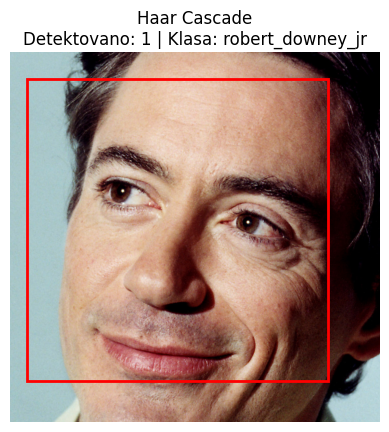

In [13]:
# Test na jednoj slučajnoj slici
img_path, label = get_random_image_path(DATASET_PATH, folders)
img_rgb = load_image_rgb(img_path)

bboxes = detect_faces_haar(img_rgb, scaleFactor=1.05, minNeighbors=6, minSize=(60,60))
show_results("Haar Cascade", img_rgb, bboxes, extra_text=f"Detektovano: {len(bboxes)} | Klasa: {label}")

### Primena na test uzorku (poređenje i vreme)

Da bismo dobili realniji utisak o stabilnosti metode, primenjujemo detektor na više slika.  
Dodatno merimo vreme izvršavanja po slici i računamo prosečno vreme (gruba procena performansi).


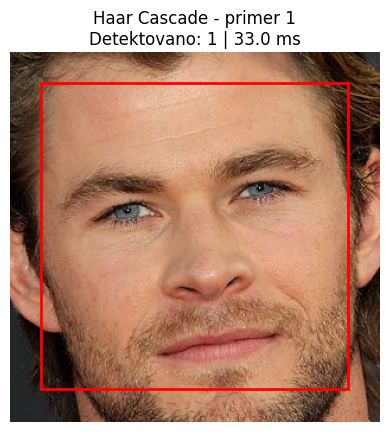

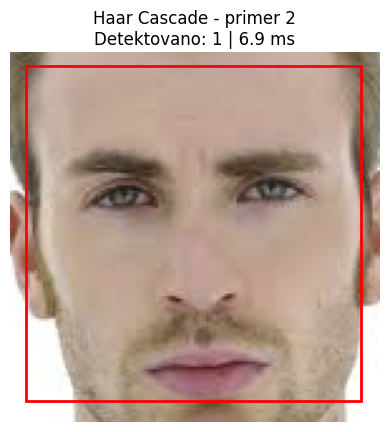

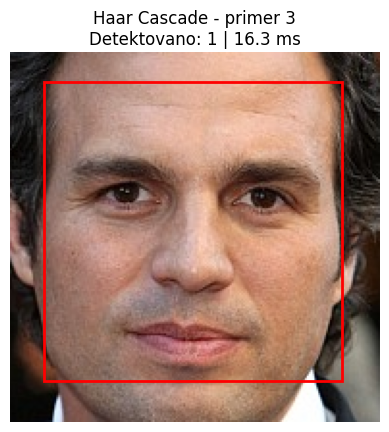

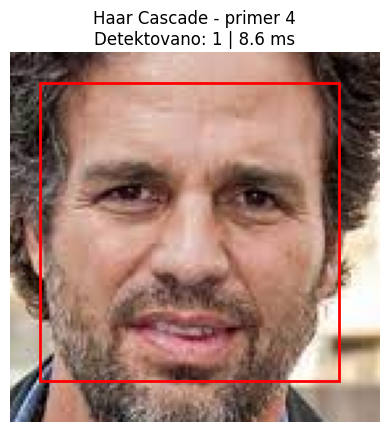

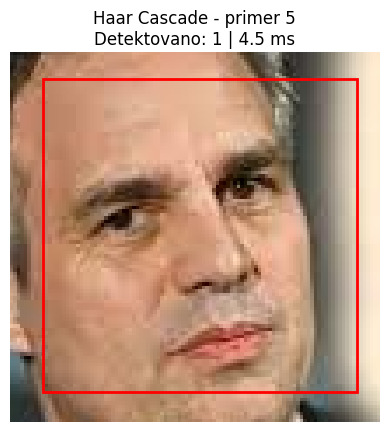

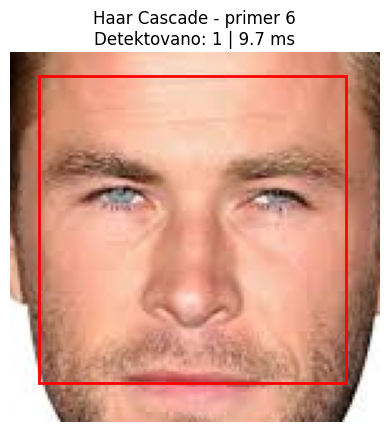

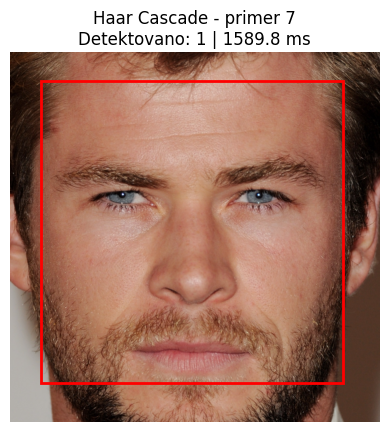

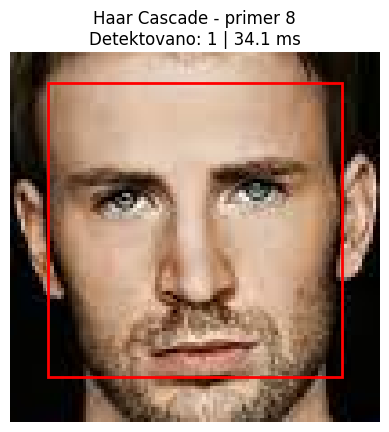

Prosečno vreme (Haar): 212.86 ms po slici
Prosečan broj detektovanih lica: 1.00


In [14]:
haar_times = []
haar_detected_counts = []

for i, img_path in enumerate(test_samples, start=1):
    img_rgb = load_image_rgb(img_path)

    start = time.time()
    bboxes = detect_faces_haar(img_rgb, scaleFactor=1.05, minNeighbors=6, minSize=(60,60))
    end = time.time()

    elapsed_ms = (end - start) * 1000
    haar_times.append(elapsed_ms)
    haar_detected_counts.append(len(bboxes))

    show_results(
        title=f"Haar Cascade - primer {i}",
        img_rgb=img_rgb,
        bboxes=bboxes,
        extra_text=f"Detektovano: {len(bboxes)} | {elapsed_ms:.1f} ms"
    )

print(f"Prosečno vreme (Haar): {np.mean(haar_times):.2f} ms po slici")
print(f"Prosečan broj detektovanih lica: {np.mean(haar_detected_counts):.2f}")


### Kratak zaključak (Haar)

Haar Cascade detektor je brz i jednostavan za korišćenje, posebno na dataset-u gde je lice uglavnom frontalno i centralno u kadru.  
Ipak, u složenijim scenarijima (više pozadine, rotacije, slabije osvetljenje) može doći do:
- propuštanja lica (false negatives),
- lažno pozitivnih detekcija (false positives).

## 3.2 Model 2: MediaPipe Face Detection

MediaPipe nudi veoma praktičan i stabilan detektor lica zasnovan na dubokom učenju.
U poređenju sa Haar metodom, često daje stabilnije rezultate na različitim uslovima (poza, osvetljenje),
uz zadržavanje dobre brzine izvršavanja.

U nastavku:
- učitavamo MediaPipe detektor,
- implementiramo funkciju koja vraća bounding box-ove u formatu `[x, y, w, h]`,
- testiramo na istom uzorku `test_samples`,
- merimo vreme izvršavanja.


In [ ]:
# Instalacija i preuzimanje modela su urađeni u sekciji 0 (na vrhu sveske)

In [15]:
import mediapipe as mp
print('MediaPipe verzija:', mp.__version__)

MediaPipe verzija: 1.2.3


In [16]:
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

# Inicijalizacija detektora (novi Tasks API)
# - model_asset_path: putanja do preuzetog modela
# - min_detection_confidence: minimalna sigurnost da bi se detekcija prihvatila
mp_options = vision.FaceDetectorOptions(
    base_options=mp_python.BaseOptions(model_asset_path='blaze_face_short_range.tflite'),
    min_detection_confidence=0.5
)
mp_detector = vision.FaceDetector.create_from_options(mp_options)

def detect_faces_mediapipe(img_rgb):
    """
    Ulaz: RGB slika
    Izlaz: lista bbox-ova [x, y, w, h]
    """
    h, w, _ = img_rgb.shape
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(img_rgb))
    result = mp_detector.detect(mp_image)

    bboxes = []
    for det in result.detections:
        bb = det.bounding_box            # koordinate su već u pikselima
        x, y = max(0, bb.origin_x), max(0, bb.origin_y)
        bw = min(w - x, bb.width)        # clamp da okvir ne izađe van slike
        bh = min(h - y, bb.height)
        bboxes.append([x, y, bw, bh])
    return bboxes

### Detekcija lica pomoću MediaPipe – primer na jednoj slici

Pre nego što se detektor primeni na veći skup slika, u nastavku je prikazan
rezultat detekcije lica na jednoj slici iz dataseta.


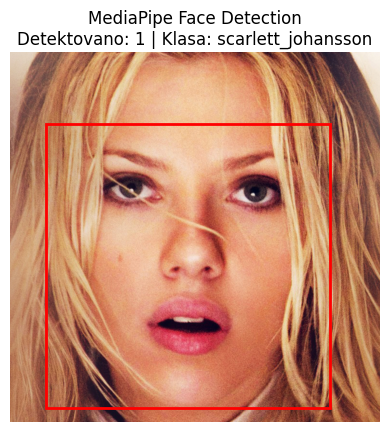

In [17]:
# Izbor jedne slučajne slike iz dataseta
img_path, label = get_random_image_path(DATASET_PATH, folders)
img_rgb = load_image_rgb(img_path)

# Detekcija lica pomoću MediaPipe funkcije
bboxes = detect_faces_mediapipe(img_rgb)

# Prikaz rezultata
show_results("MediaPipe Face Detection", img_rgb, bboxes, extra_text=f"Detektovano: {len(bboxes)} | Klasa: {label}")

### Primena na test uzorku (poređenje i vreme)

Da bismo dobili realniji utisak o stabilnosti metode, primenjujemo detektor na više slika.  
Dodatno merimo vreme izvršavanja po slici i računamo prosečno vreme (gruba procena performansi).


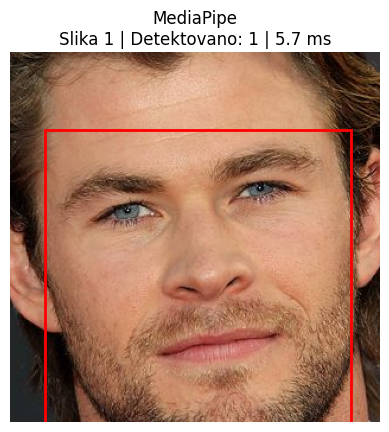

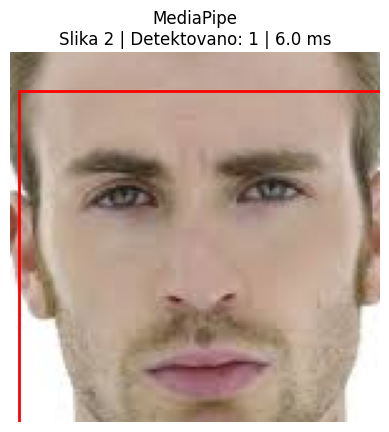

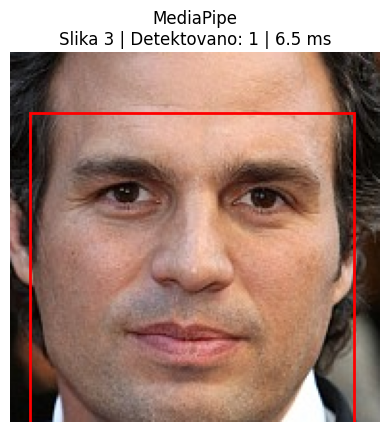

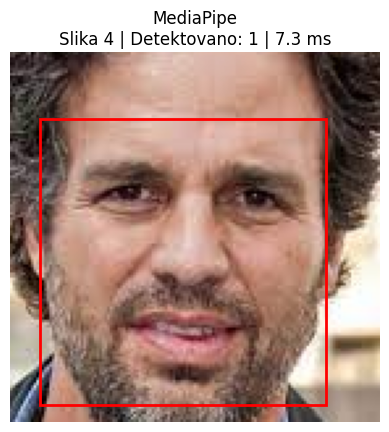

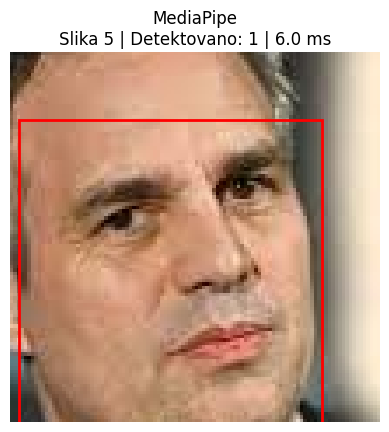

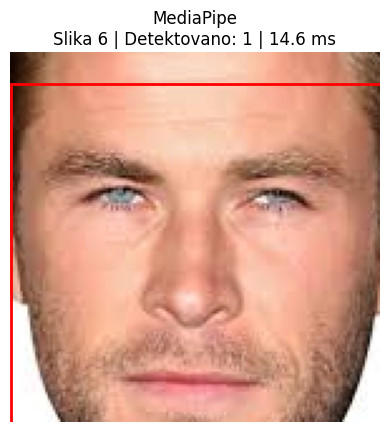

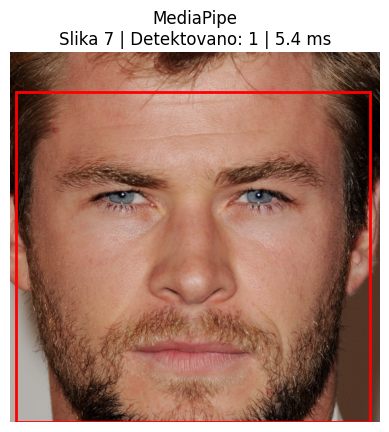

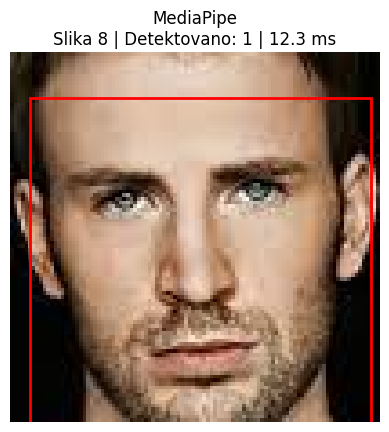

Prosečno vreme (MediaPipe): 7.97 ms po slici
Prosečan broj detektovanih lica: 1.00


In [18]:
mp_times = []
mp_counts = []

for i, img_path in enumerate(test_samples, start=1):
    img_rgb = load_image_rgb(img_path)

    start = time.time()
    bboxes = detect_faces_mediapipe(img_rgb)
    elapsed_ms = (time.time() - start) * 1000

    mp_times.append(elapsed_ms)
    mp_counts.append(len(bboxes))

    show_results("MediaPipe", img_rgb, bboxes, extra_text=f"Slika {i} | Detektovano: {len(bboxes)} | {elapsed_ms:.1f} ms")

print(f"Prosečno vreme (MediaPipe): {np.mean(mp_times):.2f} ms po slici")
print(f"Prosečan broj detektovanih lica: {np.mean(mp_counts):.2f}")


## 3.3 Model 3: Face Detection using MTCNN

MTCNN (Multi-Task Cascaded Convolutional Neural Networks) je neuronska mreža
namenjena detekciji lica i orijentira na slikama. Predložena je 2016. godine
u radu Zhang et al. i danas predstavlja jedan od najpopularnijih i
najpreciznijih pristupa za detekciju lica.

MTCNN se sastoji od tri konvolucione neuronske mreže povezane u kaskadu:
**P-Net**, **R-Net** i **O-Net**. Ovakva arhitektura omogućava visoku tačnost
detekcije uz zadržavanje performansi bliskih realnom vremenu.

U prvom koraku, ulazna slika se skalira na više rezolucija kako bi se omogućila
detekcija lica različitih veličina. Nakon toga, mreža **P-Net (Proposal Network)**
vrši inicijalno otkrivanje potencijalnih regiona lica. Ova mreža koristi nizak
prag detekcije, zbog čega proizvodi veći broj lažno pozitivnih rezultata, čak i
nakon primene NMS (Non-Maximum Suppression) algoritma. Ovakav pristup je
namerno primenjen kako bi se izbeglo propuštanje pravih detekcija.

Regionima predloženim od strane P-Net mreže zatim se bavi **R-Net (Refine Network)**,
čija je uloga filtriranje i preciznije određivanje graničnih okvira lica.
R-Net dodatno smanjuje broj lažno pozitivnih rezultata primenom NMS-a i
poboljšava kvalitet detekcije.

U završnoj fazi, **O-Net (Output Network)** vrši finalno usavršavanje graničnih
okvira. Ova mreža obezbeđuje visoku preciznost lokalizacije lica, a opciono
omogućava i detekciju orijentira na licu, kao što su položaji očiju, nosa i
uglova usana.

MTCNN pokazuje visoku robusnost u odnosu na promene veličine lica, osvetljenja
i rotacije. U poređenju sa klasičnim Viola–Jones (Haar Cascade) detektorom,
MTCNN je sporiji, ali značajno precizniji. Takođe, za razliku od klasičnih
metoda, koristi informacije u boji, jer konvolucione neuronske mreže
obrađuju RGB slike kao ulaz.


In [ ]:
# Instalacija MTCNN-a je urađena u sekciji 0 (na vrhu sveske)

In [23]:
from mtcnn.mtcnn import MTCNN

# Inicijalizacija MTCNN detektora
mtcnn_detector = MTCNN()

def detect_faces_mtcnn(img_rgb):
    """
    Ulaz:
        img_rgb – RGB slika
    Izlaz:
        lista bounding box-ova [x, y, w, h]
    """
    try:
        results = mtcnn_detector.detect_faces(img_rgb)
    except ValueError:
        # Greška u MTCNN biblioteci: kada nijedan kandidat ne prođe prve dve mreže,
        # O-Net dobija prazan ulaz i pada. To znači da lice nije pronađeno.
        results = []

    bboxes = []
    for res in results:
        x, y, w, h = res['box']

        # clamp (nekad MTCNN vrati negativne koordinate)
        x = max(0, x)
        y = max(0, y)

        bboxes.append([x, y, w, h])

    return bboxes

Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


### Detekcija lica pomoću MTCNN – primer na jednoj slici

Pre nego što se detektor primeni na veći skup slika, u nastavku je prikazan
rezultat detekcije lica na jednoj slici iz dataseta.


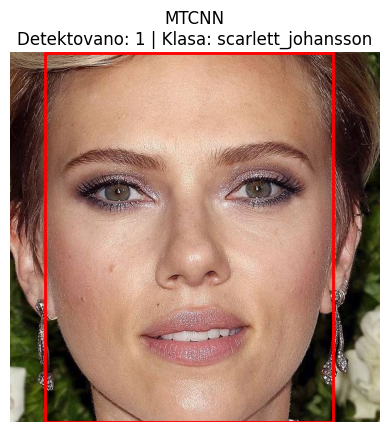

In [24]:
# Test na jednoj slučajnoj slici
img_path, label = get_random_image_path(DATASET_PATH, folders)
img_rgb = load_image_rgb(img_path)

bboxes = detect_faces_mtcnn(img_rgb)

show_results(
    "MTCNN",
    img_rgb,
    bboxes,
    extra_text=f"Detektovano: {len(bboxes)} | Klasa: {label}"
)

### Primena na test uzorku (poređenje i vreme)

Da bismo dobili realniji utisak o stabilnosti metode, primenjujemo detektor na više slika.  
Dodatno merimo vreme izvršavanja po slici i računamo prosečno vreme (gruba procena performansi).

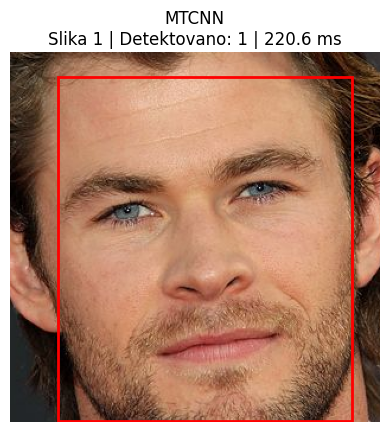

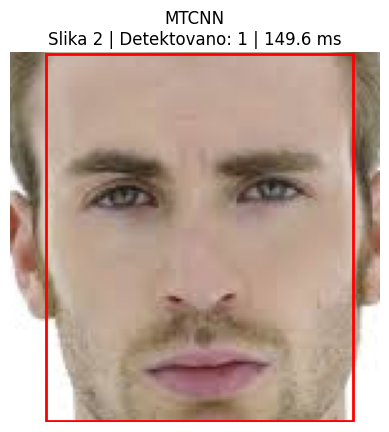

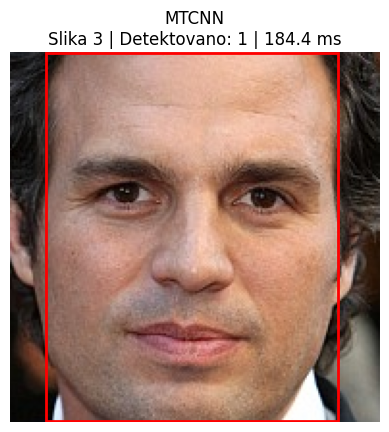

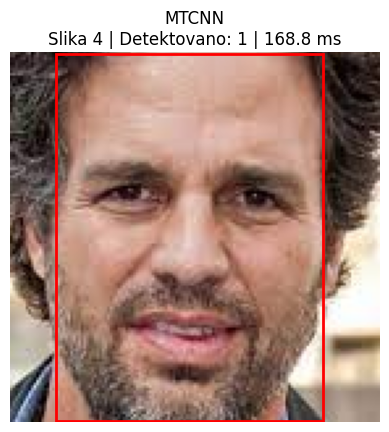

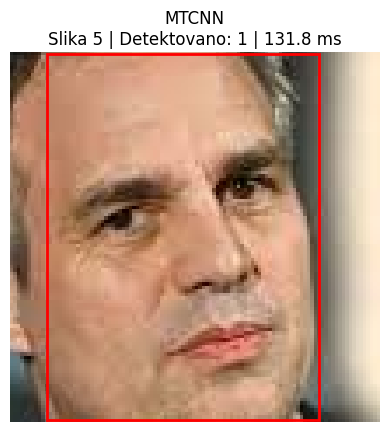

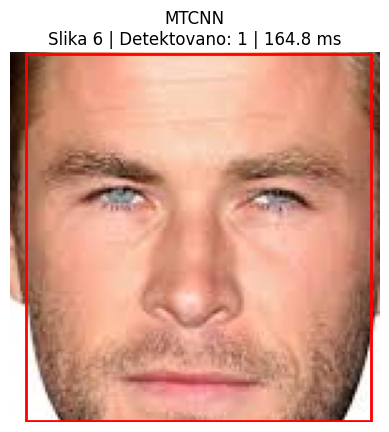

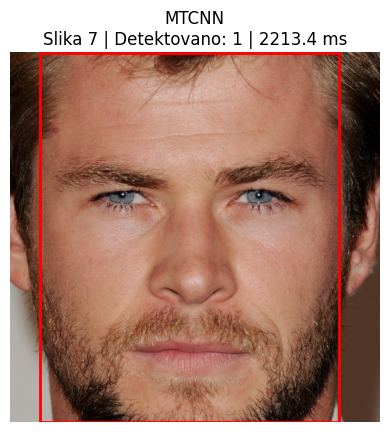

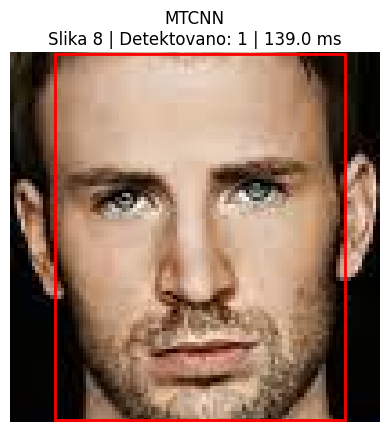

Prosečno vreme (MTCNN): 421.55 ms po slici
Prosečan broj detektovanih lica: 1.00


In [25]:
import time
import numpy as np

mtcnn_times = []
mtcnn_counts = []

for i, img_path in enumerate(test_samples, start=1):
    img_rgb = load_image_rgb(img_path)

    start = time.time()
    bboxes = detect_faces_mtcnn(img_rgb)
    elapsed_ms = (time.time() - start) * 1000

    mtcnn_times.append(elapsed_ms)
    mtcnn_counts.append(len(bboxes))

    show_results(
        "MTCNN",
        img_rgb,
        bboxes,
        extra_text=f"Slika {i} | Detektovano: {len(bboxes)} | {elapsed_ms:.1f} ms"
    )

print(f"Prosečno vreme (MTCNN): {np.mean(mtcnn_times):.2f} ms po slici")
print(f"Prosečan broj detektovanih lica: {np.mean(mtcnn_counts):.2f}")


## 3.4 Evaluacija na celom dataset-u

Do sada smo detektore gledali na 8 slika. Pošto je **svaka slika u dataset-u kropovano lice jedne osobe**, na svakoj slici treba da bude detektovano **tačno jedno lice**. To nam omogućava jednostavnu kvantitativnu evaluaciju na svih 274 slike:

- **1 detekcija** → tačno,
- **0 detekcija** → lice je propušteno (lažno negativna, FN),
- **više od 1 detekcije** → bar jedna detekcija je lažna (lažno pozitivna, FP).

Merimo i prosečno vreme po slici. Ova ćelija traje oko minut, najviše zbog MTCNN-a.

In [26]:
import pandas as pd

detektori = {
    'Haar Cascade': lambda img: detect_faces_haar(img, scaleFactor=1.05, minNeighbors=6, minSize=(60, 60)),
    'MediaPipe':    detect_faces_mediapipe,
    'MTCNN':        detect_faces_mtcnn,
}

redovi = []
for ime, detektor in detektori.items():
    broj_det, vremena = [], []
    for p in sorted(all_images):
        img = load_image_rgb(p)
        t0 = time.time()
        broj_det.append(len(detektor(img)))
        vremena.append((time.time() - t0) * 1000)
    broj_det = np.array(broj_det)
    redovi.append({
        'Metoda': ime,
        'Tačno 1 lice (%)': 100 * np.mean(broj_det == 1),
        'Propušteno, 0 lica (%)': 100 * np.mean(broj_det == 0),
        'Više od 1 lica (%)': 100 * np.mean(broj_det > 1),
        'Prosečno vreme (ms)': np.mean(vremena),
    })

rezultati_detekcije = pd.DataFrame(redovi).round(1)
rezultati_detekcije

,Metoda,Tačno 1 lice (%),"Propušteno, 0 lica (%)",Više od 1 lica (%),Prosečno vreme (ms)
0,Haar Cascade,97.1,2.9,0.0,67.4
1,MediaPipe,100.0,0.0,0.0,4.6
2,MTCNN,99.6,0.4,0.0,268.7


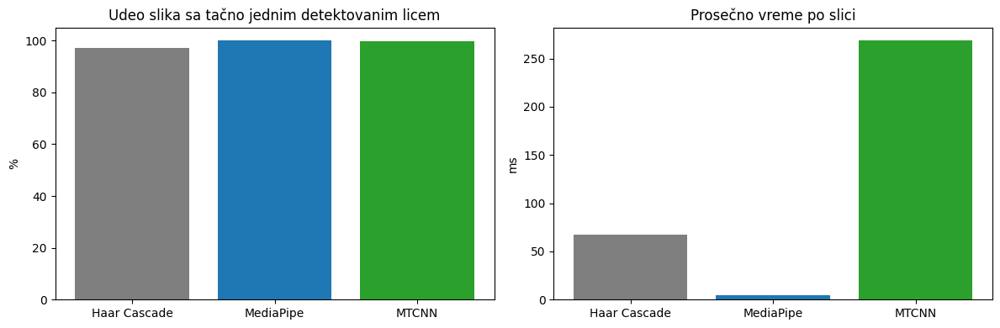

In [27]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].bar(rezultati_detekcije['Metoda'], rezultati_detekcije['Tačno 1 lice (%)'], color=['tab:gray', 'tab:blue', 'tab:green'])
axs[0].set_title('Udeo slika sa tačno jednim detektovanim licem'); axs[0].set_ylabel('%'); axs[0].set_ylim(0, 105)
axs[1].bar(rezultati_detekcije['Metoda'], rezultati_detekcije['Prosečno vreme (ms)'], color=['tab:gray', 'tab:blue', 'tab:green'])
axs[1].set_title('Prosečno vreme po slici'); axs[1].set_ylabel('ms')
plt.tight_layout(); plt.show()

## 3.5 Analiza rezultata

Tabela i grafici iznad pokazuju poređenje na celom dataset-u. Pri tumačenju obratite pažnju na sledeće:

**Brzina.** Haar Cascade ne koristi duboko učenje, ali je na ovom dataset-u sporiji od MediaPipe-a, jer sa `scaleFactor=1.05` pretražuje sliku na mnogo veličina. MediaPipe je najbrži, jer je model optimizovan za rad u realnom vremenu na mobilnim uređajima. MTCNN je najsporiji, jer sliku obrađuje kaskadom od tri konvolucione mreže na više rezolucija.

**Pouzdanost.** Pošto svaka slika sadrži tačno jedno lice, svako odstupanje od jedne detekcije je greška. Klasični Haar detektor obično češće propušta lica (rotacija, profil, osvetljenje), dok duboki modeli gotovo uvek pronađu lice.

**Napomena o merenju vremena.** Prvo pozivanje modela je uvek sporije (učitavanje i inicijalizacija), a vreme zavisi i od opterećenja Colab mašine. Zato vreme posmatramo kao grubu procenu i poredimo odnose, a ne tačne milisekunde.



### Analiza naših rezultata

| Metoda | Tačno 1 lice | Propušteno (0 lica) | Više od 1 lica | Prosečno vreme |
|---|---|---|---|---|
| Haar Cascade | 97.1% | 2.9% (8 slika) | 0% | 67.4 ms |
| MediaPipe | **100%** | 0% | 0% | **4.6 ms** |
| MTCNN | 99.6% | 0.4% (1 slika) | 0% | 268.7 ms |

**Pouzdanost detekcije.** Sva tri detektora rade vrlo dobro, što je očekivano, jer su slike kropovane i lice zauzima centralni deo kadra. Ipak, razlike postoje:
- **MediaPipe** je pronašao lice na svih 274 slike.
- **MTCNN** je propustio lice na samo jednoj slici, i to zbog greške u biblioteci: kada prve dve mreže kaskade odbace sve kandidate, treća mreža dobija prazan ulaz.
- **Haar Cascade** je propustio lice na 8 slika (2.9%). Klasični detektor je osetljiviji na lica okrenuta u stranu, nagnutu glavu i neobično osvetljenje, jer koristi ručno definisane Haar karakteristike naučene uglavnom na frontalnim licima.

**Lažno pozitivne detekcije.** Nijedan detektor nije našao više od jednog lica ni na jednoj slici. Kod Haar-a za to su zaslužni parametri `minNeighbors=6` i `minSize=(60, 60)`, koji odbacuju slabe i sitne kandidate. Cena toga je nešto više propuštenih lica: to je kompromis između lažno pozitivnih i lažno negativnih detekcija.

**Brzina.** Razlike u brzini su ogromne:
- **MediaPipe** je najbrži (oko 5 ms po slici), oko **15 puta brži od Haar-a** i oko **60 puta brži od MTCNN-a**. Iako koristi neuronsku mrežu, model je projektovan za rad u realnom vremenu na mobilnim uređajima.
- **Haar Cascade** je sporiji nego što bismo očekivali od klasičnog algoritma, jer sa `scaleFactor=1.05` pretražuje sliku na velikom broju veličina.
- **MTCNN** je najsporiji (oko 270 ms), jer sliku obrađuje na više rezolucija kroz kaskadu od tri konvolucione mreže. To je i dalje dovoljno brzo za obradu fotografija, ali ne i za video u realnom vremenu (za 30 slika u sekundi potrebno je ispod 33 ms po slici).

**Zaključak.** Na ovom dataset-u **MediaPipe je najbolji izbor**: najtačniji je i najbrži. MTCNN je skoro jednako tačan i dodatno daje ključne tačke lica (oči, nos, usta), ali je višestruko sporiji. Haar je najslabiji po tačnosti, ali ne zahteva nikakve dodatne biblioteke ni modele, jer dolazi uz OpenCV.


### Zaključak (Čas 1.)

U ovom delu case study zadatka prikazane su tri različite metode za
detekciju lica koje se razlikuju po pristupu, složenosti i
performansama.

Rezultati pokazuju da izbor metode zavisi od konkretne primene:
- za sisteme sa ograničenim resursima i jednostavne zadatke
  pogodni su klasični detektori,
- za realne aplikacije u realnom vremenu MediaPipe predstavlja
  optimalan izbor,
- za visoko precizne zadatke MTCNN pruža najbolje rezultate,
  uz veću računarsku složenost.

U narednom času fokus će biti na problemu **klasifikacije lica**,
odnosno treniranju modela koji na osnovu isečenog lica
predviđa kojoj osobi ono pripada.


### Zadaci za samostalni rad (1. čas)

1. **Uticaj parametara Haar detektora.** Za vrednosti `minNeighbors` 2, 4, 6 i 10 izračunajte udeo slika sa tačno jednim licem, sa 0 lica i sa više od jednog lica na celom dataset-u. Kako se menjaju lažno pozitivne i lažno negativne detekcije?
2. **Drugi Haar model.** Ponovite evaluaciju sa modelom `haarcascade_frontalface_default.xml` i uporedite ga sa `alt2`.
3. **Teža slika.** Učitajte grupnu fotografiju sa više lica (npr. sa interneta) i uporedite koliko lica pronalazi svaki od tri detektora. Da li je neki detektor bolji na ovoj slici nego na dataset-u? Zašto?
4. **Ključne tačke (MTCNN).** MTCNN pored okvira vraća i ključne tačke lica (`res['keypoints']`: oči, nos, uglovi usana). Nacrtajte ih na slici pomoću `plt.scatter`.

## Priprema za čas 2

In [ ]:
# Priprema za 2. čas: dataset i biblioteke (može se pokrenuti i u novoj sesiji)
import os, random, glob, time
import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf

DATASET_PATH = "cropped_images"
if not os.path.isdir(DATASET_PATH):
    !pip install -q gdown
    import gdown
    gdown.download("https://drive.google.com/uc?id=1tMVPAJYk1wILu9qxH-XfHBVK_d2sERad", output="images.zip", quiet=True)
    !unzip -q -o images.zip

folders = sorted(os.listdir(DATASET_PATH))
print("Klase:", folders)
print("Ukupno slika:", len(glob.glob(DATASET_PATH + "/*/*.png")))

# Fiksiramo seme radi ponovljivosti (rezultati će i dalje malo varirati zbog GPU-a)
random.seed(42); np.random.seed(42); tf.random.set_seed(42)

# 4. Klasifikacija lica - CNN i MobileNetV2  (2. čas)

Nakon uspešne detekcije lica, sledeći korak u sistemima za prepoznavanje lica
jeste klasifikacija – određivanje identiteta osobe kojoj detektovano lice pripada.

U ovom delu biće primenjen pristup dubokog učenja, tačnije konvolucione neuronske
mreže (CNN), koje su se pokazale kao standard u analizi slika.

S obzirom na to da je raspoloživi dataset relativno mali, koristi se tehnika
**transfer learning-a**, gde se polazi od unapred treniranog modela, a zatim se
on prilagođava konkretnom problemu klasifikacije lica Avengers likova.


## 4.1 Problem koji se rešava

Dataset je organizovan po folderima, gde svaki folder predstavlja jednu osobu
(klasu). Cilj je da model, na osnovu ulazne slike lica, predvidi kojoj klasi
(pripadniku Avengers-a) lice pripada.

Ovo je problem **višeklasne klasifikacije (multiclass)** sa 5 klasa:
- Chris Evans
- Chris Hemsworth
- Mark Ruffalo
- Robert Downey Jr
- Scarlett Johansson

### Zašto CNN?

Klasični algoritmi (npr. SVM) zahtevaju ručno definisane karakteristike (feature),
dok CNN automatski uči karakteristike direktno iz slika:
- niži slojevi uče ivice i teksture
- srednji slojevi uče delove lica (oči, nos, obris)
- viši slojevi uče kompleksne obrasce koji razlikuju osobe

Zbog toga CNN predstavlja standardni izbor za klasifikaciju slika.



In [28]:
# TensorFlow/Keras koristimo za deep learning model (CNN)
import tensorflow as tf

# ImageDataGenerator nam pomaže da automatski učitamo slike iz foldera,
# radimo resize i normalizaciju, i napravimo train/validation podelu
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# layers i models koristimo za definisanje CNN arhitekture
from tensorflow.keras import layers, models

# matplotlib za prikaz grafika treninga (accuracy/loss)
import matplotlib.pyplot as plt

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

## 4.4 Priprema podataka (preprocesiranje)

Pre nego što slike ubacimo u model, potrebno je:
1. **promeniti veličinu (resize)** – CNN očekuje fiksnu dimenziju ulaza
2. **normalizovati piksele** – vrednosti piksela su 0–255, pa ih delimo sa 255
   da bi bile u opsegu 0–1 (model brže i stabilnije uči)
3. napraviti **train/validation split** – da bismo mogli da proverimo kako
   model generalizuje na slikama koje nije video tokom treninga


### Zašto train/validation split?

Ako treniramo i testiramo model na istim slikama, dobićemo lažno optimistične
rezultate (model može da “zapamti” slike).  
Zato deo slika čuvamo za validaciju – to su slike koje model ne vidi tokom
treninga i služe da proverimo koliko dobro generalizuje.



Za osnovni CNN model korišćena je jednostavna normalizacija piksela deljenjem
vrednosti sa 255, čime se ulazni podaci mapiraju u opseg [0,1]. Ovaj pristup je
standardan kod treniranja konvolucionih neuronskih mreža od nule i ne predstavlja
ograničenje za učenje modela.

Za razliku od toga, kod primene transfer learning-a sa MobileNetV2 korišćena je
funkcija preprocess_input, koja prilagođava ulazne podatke raspodeli koju
pretrained model očekuje, čime se obezbeđuju stabilnije i tačnije performanse.

In [29]:
# Veličina ulazne slike (standardna dimenzija za mnoge pretrained modele)
IMG_SIZE = (224, 224)

# Batch size: koliko slika ide u model odjednom tokom treninga
# Manji batch -> stabilnije, ali sporije; veći batch -> brže, ali može biti nestabilno
BATCH_SIZE = 16

# ImageDataGenerator:
# - rescale=1./255 => normalizacija piksela (0–255 -> 0–1)
# - preprocessing_function=preprocess_input
#   => koristi istu normalizaciju kao MobileNetV2 tokom originalnog treninga
#   (skaliranje i centriranje piksela u opseg koji pretrained model očekuje)
# - validation_split=0.2 => 20% slika čuvamo za validaciju
def make_generators(preprocess_mode="cnn"):
    """
    preprocess_mode:
      - "cnn"       -> rescale 1./255 (CNN od nule)
      - "mobilenet" -> preprocess_input (MobileNetV2)
    """
    if preprocess_mode == "cnn":
        datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)
    elif preprocess_mode == "mobilenet":
        datagen = ImageDataGenerator(preprocessing_function=preprocess_input, validation_split=0.2)
    else:
        raise ValueError("preprocess_mode mora biti 'cnn' ili 'mobilenet'")


    # Train generator: uzima slike iz foldera cropped_images i koristi 80% (training subset)
    train_gen = datagen.flow_from_directory(
        "cropped_images",           # root folder gde su podfolderi (klase)
        target_size=IMG_SIZE,       # resize svake slike na 224x224
        batch_size=BATCH_SIZE,      # broj slika po batch-u
        class_mode="categorical",   # categorical => one-hot encoding za multiclass
        subset="training",          # koristi deo podataka za trening (80%)
        shuffle=True                # meša slike (važno za stabilan trening)
    )

    # Validation generator: koristi 20% slika (validation subset)
    val_gen = datagen.flow_from_directory(
        "cropped_images",
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        subset="validation",        # koristi deo za validaciju (20%)
        shuffle=False               # za evaluaciju često ostavljamo stabilan redosled
    )

    return train_gen, val_gen


Tokom treniranja neuronskih mreža često se javljaju sledeći problemi:
* model prestane da napreduje
* dolazi do overfitting-a
* trening traje duže nego što je potrebno

Zbog toga se koriste callback mehanizmi, koji automatski reaguju na tok
učenja i pomažu da se trening učini efikasnijim i stabilnijim.

| Callback                 | Šta radi                                                  | Zašto ga koristimo                           |
| ------------------------ | --------------------------------------------------------- | -------------------------------------------- |
| **EarlyStopping**        | Prekida trening kada se validacioni gubitak ne poboljšava | Sprečava overfitting i nepotrebno treniranje |
| **ReduceLROnPlateau**    | Smanjuje learning rate kada model “zaglavi”               | Omogućava finije podešavanje težina          |
| **restore_best_weights** | Vraća težine sa najboljim val_loss                        | Osigurava da koristimo najbolji model        |


Kako ovi callback-i rade zajedno?

1. Model trenira sa većim learning rate-om (brže učenje)
2. Ako val_loss prestane da se poboljšava:
   → ReduceLROnPlateau smanjuje learning rate
3. Ako ni nakon toga nema poboljšanja:
   → EarlyStopping zaustavlja trening
4. Model se vraća na najbolje pronađene težine

In [30]:
# EarlyStopping zaustavlja trening kada validacioni loss prestane da se poboljšava.
# time smanjujemo overfitting i štedimo vreme.
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',        # pratimo validacioni loss
    patience=3,                # koliko epoha čekamo bez poboljšanja
    restore_best_weights=True  # vraća najbolje težine (najbolji val_loss)
)

# ReduceLROnPlateau:
# Ovaj callback automatski smanjuje learning rate kada se učenje "zaglavi".
# Ako se validacioni gubitak (val_loss) ne poboljšava određeni broj epoha,
# smanjujemo korak učenja kako bi model mogao da preciznije fino podešava težine.

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',   # pratimo validacioni gubitak (meru generalizacije)
    factor=0.5,           # smanjujemo learning rate na 50% trenutne vrednosti
    patience=2,           # čekamo 2 epohe bez poboljšanja pre smanjenja
    min_lr=1e-6           # donja granica learning rate-a (da ne postane previše mali)
)

## **4.5 Jednostavan CNN model**

In [31]:
train_gen1, val_gen1 = make_generators("cnn")

Found 221 images belonging to 5 classes.
Found 53 images belonging to 5 classes.


In [32]:
# Jednostavan CNN model (didaktički primer)
# Ideja: nekoliko konvolucionih slojeva + pooling + dense slojevi na kraju

model_cnn = models.Sequential([
    # Conv2D uči lokalne obrasce (ivice, teksture)
    # 32 filtera znači da u ovom sloju učimo 32 različite vrste obrazaca
    layers.Input(shape=(224, 224, 3)),
    layers.Conv2D(32, (3,3), activation='relu'),

    # MaxPooling smanjuje dimenzije i čuva najvažnije informacije
    layers.MaxPooling2D(2,2),

    # Drugi conv sloj (više filtera => složenije karakteristike)
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    # Treći conv sloj
    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    # Flatten pretvara 2D feature map u 1D vektor
    layers.Flatten(),

    # Dense sloj kombinuje naučene karakteristike
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),

    # Izlazni sloj:
    # - 5 neurona => 5 klasa
    # - softmax => daje verovatnoće po klasama koje se sabiraju na 1
    layers.Dense(5, activation='softmax')
])

# Kompajliranje modela:
# optimizer=adam => popularan i stabilan optimizer
# loss=categorical_crossentropy => standardna funkcija greške za multiclass
# metrics=['accuracy'] => pratimo tačnost tokom treninga
model_cnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Prikaz arhitekture modela
model_cnn.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,605 (42.61 MB)

 Trainable params: 11,169,605 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [33]:
# Treniranje modela:
# epochs=30 => model će proći 30 puta kroz trening skup
# (na malom datasetu često je dovoljno 5–15 epoha za demonstraciju)
history = model_cnn.fit(
    train_gen1,                 # trening podaci
    validation_data=val_gen1,   # validacioni podaci
    epochs=30,                 # možemo staviti više, jer EarlyStopping prekida ranije
    callbacks=[early_stop, reduce_lr]
)


Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - accuracy: 0.2624 - loss: 1.7269 - val_accuracy: 0.2453 - val_loss: 1.6058 - learning_rate: 0.0010
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step - accuracy: 0.2670 - loss: 1.5966 - val_accuracy: 0.2264 - val_loss: 1.6016 - learning_rate: 0.0010
Epoch 3/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step - accuracy: 0.4072 - loss: 1.4451 - val_accuracy: 0.4340 - val_loss: 1.4520 - learning_rate: 0.0010
Epoch 4/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step - accuracy: 0.5611 - loss: 1.1333 - val_accuracy: 0.5094 - val_loss: 1.3402 - learning_rate: 0.0010
Epoch 5/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step - accuracy: 0.6561 - loss: 0.8877 - val_accuracy: 0.5660 - val_loss: 1.1863 - learning_rate: 0.0010
Epoch 6/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step - accuracy: 0.7738 - loss: 0.6579 - val_accuracy: 0.5660 - val_loss: 1.1942 - learning_rate: 0.0010
Epoch 7/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step - accuracy: 0.8597 - loss: 0.4007 - val_accuracy: 

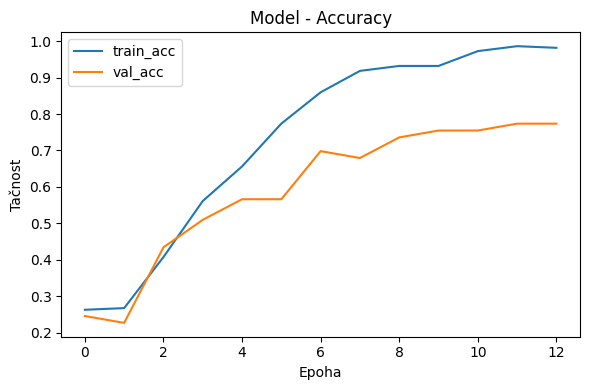

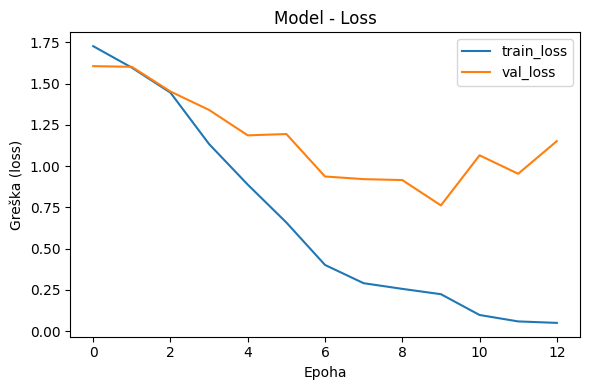

In [34]:
import matplotlib.pyplot as plt

# Funkcija koja crta tok treninga:
# - accuracy (tačnost) na trening i validacionom skupu
# - loss (greška) na trening i validacionom skupu
def plot_history(history, title="Trening"):
    train_acc = history.history.get("accuracy", [])
    val_acc   = history.history.get("val_accuracy", [])
    train_loss = history.history.get("loss", [])
    val_loss   = history.history.get("val_loss", [])

    # Accuracy graf
    plt.figure(figsize=(6,4))
    plt.plot(train_acc, label="train_acc")
    plt.plot(val_acc, label="val_acc")
    plt.title(f"{title} - Accuracy")
    plt.xlabel("Epoha")
    plt.ylabel("Tačnost")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Loss graf
    plt.figure(figsize=(6,4))
    plt.plot(train_loss, label="train_loss")
    plt.plot(val_loss, label="val_loss")
    plt.title(f"{title} - Loss")
    plt.xlabel("Epoha")
    plt.ylabel("Greška (loss)")
    plt.legend()
    plt.tight_layout()
    plt.show()

# Poziv funkcije (history je rezultat model.fit(...))
plot_history(history, title="Model")


Na graficima je prikazan tok treninga za trening skup (plava linija) i validacioni skup (narandžasta linija).

**Tačnost (accuracy)**

Trening tačnost brzo raste i već oko 7. epohe prelazi 90%, a na kraju dostiže skoro 100%. Model, dakle, gotovo savršeno klasifikuje slike koje je video tokom učenja.

Validaciona tačnost takođe raste, ali sporije, i zaustavlja se na oko **77%**. Od otprilike 8. epohe se gotovo ne menja, iako trening tačnost i dalje raste.

**Greška (loss)**

Trening loss stalno opada i na kraju je blizu nule.

Validacioni loss opada do **9. epohe**, gde dostiže minimum (oko 0.76), a zatim počinje da **raste** (preko 1.0), dok trening loss i dalje pada.

**Zaključak: overfitting**

Razilaženje krivih, a naročito rast validacionog loss-a posle 9. epohe, jasan je znak overfitting-a: model počinje da „pamti” trening slike umesto da uči opšte karakteristike lica. To je očekivano, jer model ima preko 11 miliona parametara, a trening skup samo 221 sliku.

Upravo zato koristimo **EarlyStopping**: pošto se validacioni loss nije poboljšao tri epohe zaredom (10, 11 i 12), trening je zaustavljen posle 12. epohe, a zahvaljujući opciji `restore_best_weights=True` model je vraćen na težine iz **9. epohe**, gde je validacioni loss bio najmanji.

Zanimljivo je da validaciona tačnost posle 9. epohe ostaje ista ili čak malo raste, dok loss raste. Loss ne meri samo da li je predikcija tačna, nego i **koliko je model siguran**. Kada model na nekim validacionim slikama pogreši, ali sa velikom sigurnošću, loss raste i kada se broj tačnih predikcija ne menja.

In [35]:
# evaluate() vraća metrike koje si naveo u model.compile(...)
val_loss, val_acc = model_cnn.evaluate(val_gen1, verbose=0)

print(f"Validaciona tačnost (val_accuracy): {val_acc:.4f}")
print(f"Validacioni loss (val_loss):       {val_loss:.4f}")

Validaciona tačnost (val_accuracy): 0.7547
Validacioni loss (val_loss):       0.7617


Nakon završenog treninga, model je evaluiran na validacionom skupu, koji sadrži slike koje model nije video tokom treninga. Zahvaljujući EarlyStopping-u, evaluiraju se težine iz najbolje epohe (9. epoha).

**Dobijeni rezultati su:**
* Validaciona tačnost (val_accuracy): 0.7547, odnosno **40 od 53** slike je tačno klasifikovano
* Validaciona greška (val_loss): 0.7617

**Tumačenje rezultata**

Za pet klasa nasumično pogađanje daje tačnost od 20%, pa tačnost od oko 75% pokazuje da je mreža trenirana od nule, na samo 221 slici, uspela da nauči karakteristike koje razlikuju osobe.

Poređenjem sa trening rezultatima (trening tačnost skoro 100%, trening loss blizu nule) vidi se jasan overfitting, što je očekivano s obzirom na:
* malu veličinu skupa podataka,
* veliki broj parametara modela (preko 11 miliona),
* sličnosti između pojedinih klasa,
* treniranje modela od nule, bez prethodnog znanja.

**Napomena o ponovljivosti.** Prošlogodišnje pokretanje istog koda dalo je tačnost 0.8113 (43 od 53 slike). Razlika od 3 slike posledica je nasumičnih početnih težina, drugih verzija biblioteka i veoma malog validacionog skupa: svaka slika pomera tačnost za skoro 2 procentna poena. Zato rezultate na malim skupovima tumačimo oprezno, a pouzdaniji zaključak bi zahtevao više ponovljenih treniranja ili veći skup podataka.

Classification report (precision/recall/f1):

                    precision    recall  f1-score   support

       chris_evans       0.75      0.60      0.67        10
   chris_hemsworth       0.62      0.80      0.70        10
      mark_ruffalo       0.86      0.92      0.89        13
  robert_downey_jr       0.62      0.50      0.56        10
scarlett_johansson       0.90      0.90      0.90        10

          accuracy                           0.75        53
         macro avg       0.75      0.74      0.74        53
      weighted avg       0.76      0.75      0.75        53

Confusion matrix (broj tačnih/pogrešnih po klasama):

[[ 6  3  0  1  0]
 [ 1  8  0  0  1]
 [ 0  0 12  1  0]
 [ 1  2  2  5  0]
 [ 0  0  0  1  9]]


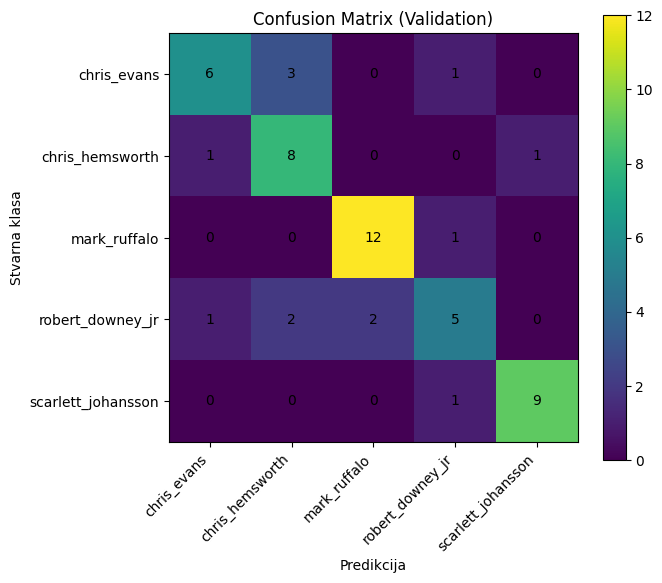

In [36]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt

# Reset generatora da bi predikcije krenule od prve slike (bitno!)
val_gen1.reset()

# MODEL.predict daje verovatnoće po klasama (softmax izlaz)
y_prob = model_cnn.predict(val_gen1, verbose=0)

# Najveća verovatnoća => predikovana klasa
y_pred = np.argmax(y_prob, axis=1)

# Prave klase generator već zna (labeli po redosledu slika)
y_true = val_gen1.classes

# Nazivi klasa iz foldera (npr. chris_evans, mark_ruffalo, ...)
class_names = list(val_gen1.class_indices.keys())

print("Classification report (precision/recall/f1):\n")
print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion matrix: red = stvarna klasa, kolona = predikovana klasa
cm = confusion_matrix(y_true, y_pred)

print("Confusion matrix (broj tačnih/pogrešnih po klasama):\n")
print(cm)

# Vizuelni prikaz confusion matrix
plt.figure(figsize=(7,6))
plt.imshow(cm)
plt.title("Confusion Matrix (Validation)")
plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
plt.yticks(range(len(class_names)), class_names)
plt.colorbar()
plt.xlabel("Predikcija")
plt.ylabel("Stvarna klasa")

# Ispis brojeva u ćelijama matrice radi lakše interpretacije
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()


**Analiza po klasama**

Redosled klasa u matrici konfuzije (i u redovima i u kolonama): Chris Evans, Chris Hemsworth, Mark Ruffalo, Robert Downey Jr, Scarlett Johansson. Redovi su stvarne klase, a kolone predviđene.

**1. Scarlett Johansson** (precision 0.90, recall 0.90, f1 0.90)
* Najbolje prepoznata klasa: 9 od 10 slika je tačno klasifikovano, a samo jedna je zamenjena za Roberta Downey Jr-a.
* I kada model kaže „Scarlett Johansson”, skoro uvek je u pravu (9 od 10 takvih predikcija). Kao jedina ženska osoba u dataset-u, njene crte lica se jasno razlikuju od ostalih klasa.

**2. Mark Ruffalo** (precision 0.86, recall 0.92, f1 0.89)
* Vrlo dobri rezultati: 12 od 13 slika je tačno klasifikovano, a jedna je zamenjena za Roberta Downey Jr-a.
* Preciznost je 0.86, jer je model dve slike Roberta Downey Jr-a pogrešno proglasio Markom Ruffalom.

**3. Chris Hemsworth** (precision 0.62, recall 0.80, f1 0.70)
* Model pronalazi većinu njegovih slika (8 od 10), ali ima **nisku preciznost**: kada kaže „Chris Hemsworth”, u pravu je u samo 8 od 13 slučajeva.
* Model u ovu klasu „gura” slike drugih osoba: 3 slike Chrisa Evansa i 2 slike Roberta Downey Jr-a.

**4. Chris Evans** (precision 0.75, recall 0.60, f1 0.67)
* Tačno je klasifikovano 6 od 10 slika. Čak 3 slike su zamenjene za **Chrisa Hemswortha**, a jedna za Roberta Downey Jr-a.
* Ovo je **najčešća pojedinačna greška** u matrici. Dvojica Krisa su sličnog godišta i tipa lica, često sa bradom i sličnom frizurom, pa ih mreža trenirana od nule teško razdvaja.

**5. Robert Downey Jr** (precision 0.62, recall 0.50, f1 0.56)
* Najproblematičnija klasa: tačno je prepoznata samo polovina slika (5 od 10).
* Greške su raspršene po tri klase: 2 slike su proglašene Hemsworthom, 2 Ruffalom i 1 Evansom. Model, dakle, nije naučio karakteristike koje jasno izdvajaju ovu osobu.
* I preciznost je niska (5 od 8), jer se u ovu klasu svrstavaju i slike drugih osoba.

**Globalne metrike**
* Ukupna tačnost: 0.75 (40 od 53 slike).
* Macro avg F1: 0.74. Svaka klasa ima istu težinu, pa ovaj broj pokazuje prosečan kvalitet po osobi.
* Weighted avg F1: 0.75. Klase su ponderisane brojem slika, a pošto su klase skoro izbalansirane, razlika u odnosu na macro je mala.

**Zaključak evaluacije**

Model jasno razlikuje osobe sa izraženijim karakteristikama (Scarlett Johansson, Mark Ruffalo), dok najviše grešaka pravi između **Chrisa Evansa i Chrisa Hemswortha**, kao i kod **Roberta Downey Jr-a**, čije se slike rasipaju na više klasa.

Zanimljivo je da je u prošlogodišnjem pokretanju istog koda najčešća zabuna bila između Marka Ruffala i Roberta Downey Jr-a, a sada je između dva Krisa. I to potvrđuje da su rezultati na ovako malom skupu podataka nestabilni i da zavise od nasumičnih početnih težina.

Ovi rezultati pokazuju da CNN treniran od nule predstavlja dobar polazni model (baseline), ali i da postoji prostor za poboljšanje primenom transfer learning-a.

In [37]:
import cv2
import random
import os
import numpy as np
import matplotlib.pyplot as plt

# Pomoćna funkcija za učitavanje i resize slike (za prikaz)
def load_img_rgb(path, img_size=(224,224)):
    img_bgr = cv2.imread(path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_rgb = cv2.resize(img_rgb, img_size)
    return img_rgb

# Priprema liste putanja slika iz validacionog generatora
val_paths = val_gen1.filepaths

# Predikcije već imamo: y_true, y_pred, class_names
# Nađi indekse tačnih i pogrešnih predikcija
correct_idxs = [i for i in range(len(y_true)) if y_pred[i] == y_true[i]]
wrong_idxs   = [i for i in range(len(y_true)) if y_pred[i] != y_true[i]]

print(f"Tačno klasifikovano: {len(correct_idxs)} / {len(y_true)}")
print(f"Pogrešno klasifikovano: {len(wrong_idxs)} / {len(y_true)}")

Tačno klasifikovano: 40 / 53
Pogrešno klasifikovano: 13 / 53


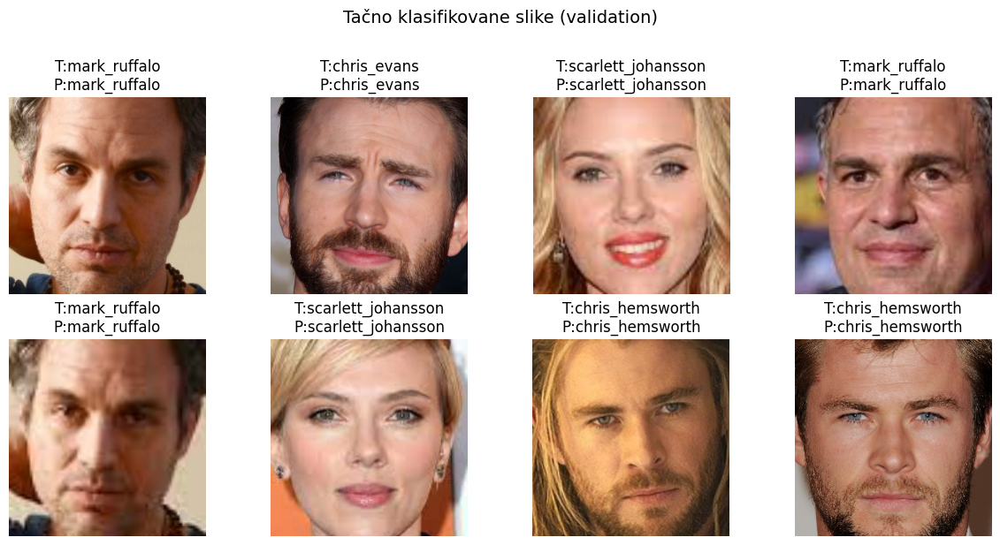

In [38]:
# Koliko primera da prikažemo
N = 8

# Ako nema dovoljno tačnih, uzmi koliko ima
sample_idxs = random.sample(correct_idxs, k=min(N, len(correct_idxs)))

plt.figure(figsize=(12,6))
for k, idx in enumerate(sample_idxs, start=1):
    path = val_paths[idx]
    img = load_img_rgb(path, IMG_SIZE)

    true_name = class_names[y_true[idx]]
    pred_name = class_names[y_pred[idx]]

    plt.subplot(2,4,k)
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"T:{true_name}\nP:{pred_name}")

plt.suptitle("Tačno klasifikovane slike (validation)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()


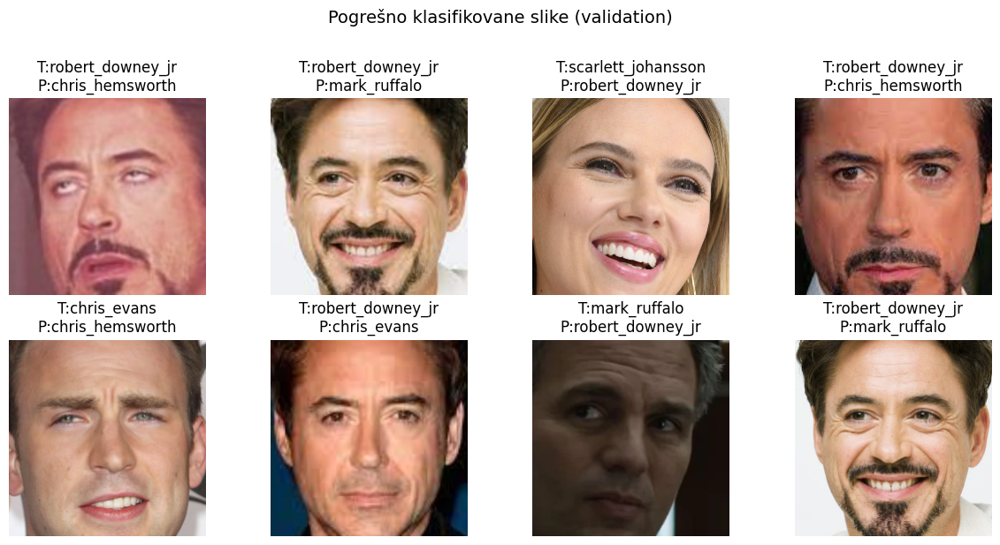

In [39]:
N = 8
sample_idxs = random.sample(wrong_idxs, k=min(N, len(wrong_idxs)))

plt.figure(figsize=(12,6))
for k, idx in enumerate(sample_idxs, start=1):
    path = val_paths[idx]
    img = load_img_rgb(path, IMG_SIZE)

    true_name = class_names[y_true[idx]]
    pred_name = class_names[y_pred[idx]]

    plt.subplot(2,4,k)
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"T:{true_name}\nP:{pred_name}")

plt.suptitle("Pogrešno klasifikovane slike (validation)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()


Na osnovu dobijenih rezultata može se zaključiti da je implementirani CNN model uspešno naučio da razlikuje osnovne karakteristike lica iz posmatranog dataseta. Tačno je klasifikovano 40 od 53 validacione slike, odnosno tačnost je oko 75%. To ukazuje na solidne performanse modela, posebno imajući u vidu mali broj dostupnih slika po klasi i činjenicu da je mreža trenirana od nule, bez prethodnog znanja.

Analiza matrice konfuzije i klasifikacionog izveštaja pokazuje da model vrlo dobro prepoznaje klase Scarlett Johansson i Mark Ruffalo, za koje su ostvarene visoke vrednosti preciznosti i odziva. Najviše grešaka javlja se kod klase Robert Downey Jr, čije se slike pogrešno svrstavaju u čak tri različite klase, kao i između vizuelno sličnih klasa Chris Evans i Chris Hemsworth.

Pregled tačno i pogrešno klasifikovanih slika daje dodatni uvid u to **zašto** model greši:
* **Tačno klasifikovane slike** su uglavnom frontalne, sa neutralnim izrazom lica i dobrim, ujednačenim osvetljenjem.
* **Pogrešno klasifikovane slike** često imaju neki „neobičan” element:
  * **izražen osmeh ili grimasu**: širok osmeh Roberta Downey Jr-a i Scarlett Johansson, kao i grimasa Chrisa Evansa, menjaju izgled lica u odnosu na većinu trening slika;
  * **loše ili neobično osvetljenje**: vrlo tamna slika Marka Ruffala i slika Roberta Downey Jr-a sa izraženom ružičastom nijansom;
  * **neobičnu pozu ili izraz**, kao što su zakolutane oči ili glava okrenuta u stranu.

Model, dakle, nije naučio samo „identitet” osobe, nego je delimično zavisan od izraza lica i uslova snimanja. To je tipično za male datasete, u kojima nema dovoljno primera iste osobe u različitim situacijama.

Uočeno je i jasno razilaženje između trening i validacionih rezultata (trening tačnost skoro 100%, validaciona oko 75%), što ukazuje na overfitting, uprkos primeni regularizacionih tehnika kao što su Dropout i EarlyStopping. Takvo ponašanje je očekivano za mali dataset i model sa preko 11 miliona parametara. Ono potvrđuje da je CNN treniran od nule dobar polazni model (baseline), ali ne i optimalno rešenje za prepoznavanje lica.

Zbog navedenih ograničenja, u nastavku će biti primenjen napredniji pristup zasnovan na transfer learning-u, korišćenjem unapred treniranog modela MobileNetV2, sa ciljem postizanja veće tačnosti i stabilnijeg učenja.

# **4.6 Transfer learning – MobileNetV2**

Nakon osnovnog CNN modela, sledeći korak je primena transfer learning-a.
Ideja transfer learning-a je da se iskoriste znanja modela koji je već treniran
na velikom i raznovrsnom skupu podataka (npr. ImageNet), umesto treniranja
mreže od nule.

U ovom radu koristi se MobileNetV2, lagan i efikasan CNN model koji se
često koristi u realnim aplikacijama (mobilni uređaji, embedded sistemi).

**Zašto MobileNetV2?**
* treniran na milionima slika (ImageNet)
* uči veoma dobre opšte vizuelne karakteristike
* zahteva manje resursa u odnosu na teže modele (ResNet, VGG)
* odličan izbor za mali dataset

In [40]:
train_gen2, val_gen2 = make_generators("mobilenet")

Found 221 images belonging to 5 classes.
Found 53 images belonging to 5 classes.


In [41]:
def deprocess_mobilenet(x):
    """
    Vraća MobileNetV2 preprocessovane piksele iz [-1,1] u [0,1]
    ISKLJUČIVO za vizuelni prikaz.
    """
    x = (x + 1.0) / 2.0
    return np.clip(x, 0.0, 1.0)


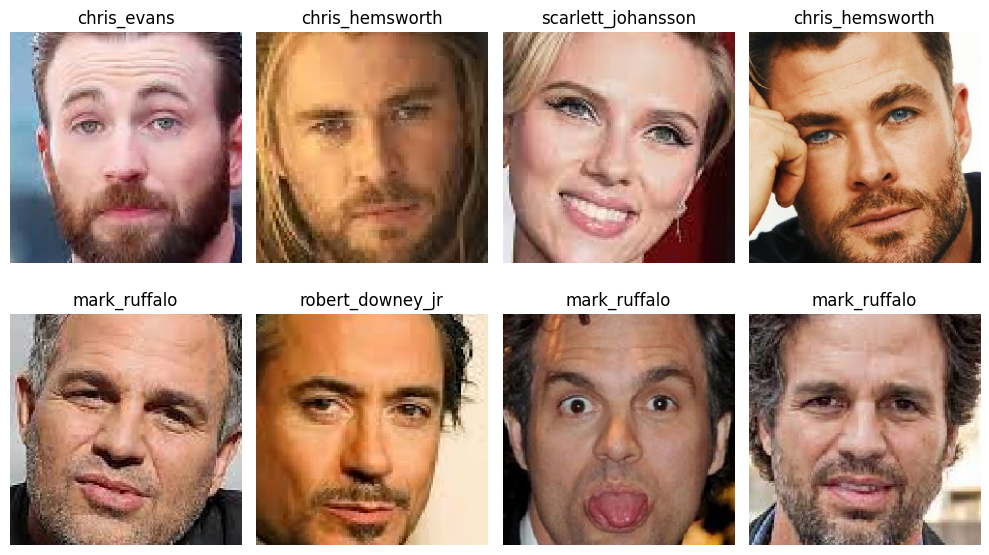

In [42]:
import numpy as np
import matplotlib.pyplot as plt

# Uzmi jedan batch iz train generatora
x_batch, y_batch = next(train_gen2)

# Imena klasa (redosled iz generatora)
class_names = list(train_gen2.class_indices.keys())

plt.figure(figsize=(10, 6))
for i in range(min(8, len(x_batch))):
    plt.subplot(2, 4, i+1)

    img = deprocess_mobilenet(x_batch[i])
    plt.imshow(img)

    label_id = np.argmax(y_batch[i])
    plt.title(class_names[label_id])
    plt.axis("off")
plt.tight_layout()
plt.show()


In [46]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, models

# Broj klasa koje model treba da prepoznaje
# Automatski se preuzima iz generatora (broj foldera = broj klasa)
NUM_CLASSES = train_gen2.num_classes

# Učitavanje unapred treniranog MobileNetV2 modela
# - input_shape=(224,224,3): očekuje RGB slike dimenzije 224x224
# - include_top=False: izbacujemo originalni klasifikacioni deo (1000 ImageNet klasa)
# - weights="imagenet": koristimo težine naučene na ImageNet datasetu
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Transfer learning – faza 1:
# Zamrzavamo sve slojeve baznog modela.
# To znači da se njihove težine NE MENJAJU tokom treninga.
# MobileNetV2 se ovde koristi kao extractor karakteristika (feature extractor).
base_model.trainable = False

# Definisanje kompletne arhitekture modela:
# 1) base_model izdvaja karakteristike sa slike
# 2) GlobalAveragePooling2D smanjuje dimenzije feature mapa u jedan vektor
#    (manje parametara i manji rizik od overfitting-a nego Flatten)
# 3) Dropout smanjuje overfitting nasumičnim "gašenjem" neurona tokom treninga
# 4) Dense sloj sa softmax aktivacijom daje verovatnoće po klasama
model_m2 = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

# Kompajliranje modela:
# - Adam optimizer: stabilan i često korišćen za CNN modele
# - learning_rate=1e-3: veći LR je dozvoljen jer treniramo samo "glavu"
# - categorical_crossentropy: standardna loss funkcija za multiclass klasifikaciju
# - accuracy: pratimo tačnost tokom treninga i validacije
model_m2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Prikaz strukture modela:
# - broj slojeva
# - oblik izlaza svakog sloja
# - broj trenabilnih i netrenabilnih parametara
model_m2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [47]:
history_m2 = model_m2.fit(
    train_gen2,                 # generator za trening podatke
    validation_data=val_gen2,   # generator za validaciju (neviđeni podaci)
    epochs=100,                 # maksimalan broj epoha
    # EarlyStopping:
    # - zaustavlja trening kada se validacioni loss ne poboljšava
    # - sprečava overfitting i nepotrebno dugo treniranje
    #
    # ReduceLROnPlateau:
    # - smanjuje learning rate kada učenje "zapne"
    # - omogućava finije podešavanje težina
    callbacks=[
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6),
    ]
)

Epoch 1/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step - accuracy: 0.2670 - loss: 1.7906 - val_accuracy: 0.2075 - val_loss: 1.7031 - learning_rate: 0.0010
Epoch 2/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.4072 - loss: 1.3877 - val_accuracy: 0.4528 - val_loss: 1.5194 - learning_rate: 0.0010
Epoch 3/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.5792 - loss: 1.0868 - val_accuracy: 0.4906 - val_loss: 1.3635 - learning_rate: 0.0010
Epoch 4/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.6425 - loss: 0.9501 - val_accuracy: 0.4717 - val_loss: 1.2761 - learning_rate: 0.0010
Epoch 5/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.7421 - loss: 0.7981 - val_accuracy: 0.5660 - val_loss: 1.1308 - learning_rate: 0.0010
Epoch 6/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.7602 - loss: 0.7288 - val_accuracy: 0.6981 - val_loss: 1.0398 - learning_rate: 0.0010
Epoch 7/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.8371 - loss: 0.6154 - val_acc

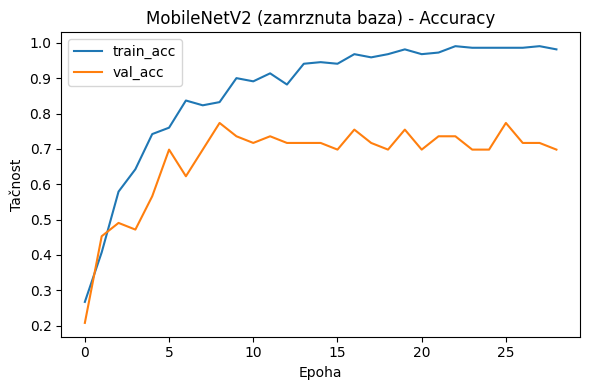

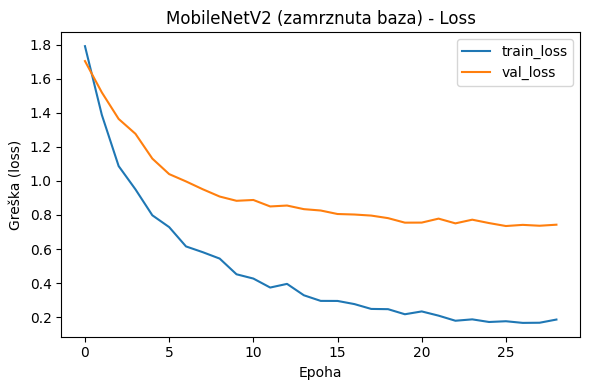

In [48]:
# Isti grafici kao za CNN, ali sada za MobileNetV2 (funkcija plot_history je definisana ranije)
plot_history(history_m2, title="MobileNetV2 (zamrznuta baza)")

**Kratko tumačenje grafika**

**Trening skup**
* Trening tačnost brzo raste i od otprilike 13. epohe je iznad 90%, a na kraju oko 98%.
* Trening loss stalno opada, do oko 0.2. Model dobro uči trening podatke, iako se trenira samo mali „vrh” mreže (oko 6 hiljada parametara), dok je baza zamrznuta.

**Validacioni skup**
* Validacioni loss **ravnomerno opada** tokom celog treninga (sa oko 1.7 na oko 0.74) i na kraju se stabilizuje. Za razliku od CNN-a od nule, **ne počinje da raste**.
* Validaciona tačnost brzo raste do oko 75% (već oko 8. epohe), a zatim **osciluje između 70% i 77%**. Oscilacije su posledica malog validacionog skupa: svaka slika menja tačnost za skoro 2 procentna poena.
* Trening je trajao 29 epoha. EarlyStopping ga je prekinuo kada se validacioni loss tri epohe zaredom nije poboljšao, a model je vraćen na težine sa najmanjim validacionim loss-om.

**Ključna razlika u odnosu na CNN od nule**

| | CNN od nule | MobileNetV2 (zamrznuta baza) |
|---|---|---|
| Ponašanje validacionog loss-a | pada do 9. epohe, zatim **raste** (preko 1.0) | **ravnomerno pada** i stabilizuje se |
| Najmanji validacioni loss | oko 0.76 | oko 0.74 |
| Validaciona tačnost | oko 75% | oko 70–77% |
| Broj parametara koji se treniraju | preko 11 miliona | oko 6 hiljada |

Validaciona tačnost oba modela je **slična**, ali MobileNetV2 uči **stabilnije**: validacioni loss ne raste, pa model ne ulazi u izražen overfitting kao CNN od nule. Razlog je to što se trenira samo mali broj parametara, dok karakteristike slike daje baza već naučena na milionima ImageNet slika.

Razmak između trening i validacionih krivih i dalje postoji (trening loss oko 0.2, validacioni oko 0.74), pa je prisutan **blag overfitting**, ali je mnogo manje izražen i ne pogoršava se tokom treninga.

Dodatno poboljšanje pokušaćemo **fine-tuning-om**: odmrzavanjem poslednjih slojeva baze, kako bi se karakteristike prilagodile licima.

In [49]:
# evaluate() vraća metrike koje si naveo u model.compile(...)
val_loss, val_acc = model_m2.evaluate(val_gen2, verbose=0)

print(f"Validaciona tačnost (val_accuracy): {val_acc:.4f}")
print(f"Validacioni loss (val_loss):       {val_loss:.4f}")

Validaciona tačnost (val_accuracy): 0.7736
Validacioni loss (val_loss):       0.7351


Na osnovu dobijenih rezultata može se uočiti da model zasnovan na MobileNetV2 arhitekturi pokazuje stabilno ponašanje tokom treninga i validacije.

**Dobijeni rezultati su:**
* Validaciona tačnost (val_accuracy): 0.7736, odnosno **41 od 53** slike je tačno klasifikovana
* Validaciona greška (val_loss): 0.7351

Validaciona tačnost od približno 77% ukazuje da model uspeva da generalizuje naučene karakteristike i na slike koje nisu korišćene tokom treninga. Ovaj rezultat je značajan imajući u vidu mali obim dataseta i veliku sličnost između pojedinih klasa (lica različitih glumaca).

Validacioni gubitak (loss) iznosi 0.7351, što ukazuje da model i dalje pravi izvesne greške u proceni verovatnoća po klasama. Takvo ponašanje je očekivano kod problema prepoznavanja lica na malim skupovima podataka, gde su razlike između klasa često suptilne.

**Poređenje sa CNN-om od nule**

| Model | Val_accuracy | Tačno klasifikovano | Val_loss |
|---|---|---|---|
| CNN od nule | 0.7547 | 40 / 53 | 0.7617 |
| MobileNetV2 (zamrznuta baza) | **0.7736** | **41 / 53** | **0.7351** |

MobileNetV2 ima nešto višu tačnost i niži validacioni loss, uz **oko 1700 puta manje parametara** koji se treniraju (oko 6 hiljada prema preko 11 miliona). Razlika u tačnosti je ipak samo **jedna slika**, pa ne možemo tvrditi da je MobileNetV2 značajno tačniji. Njegova prava prednost je **stabilnije učenje** bez izraženog overfitting-a.

Classification report (precision/recall/f1):

                    precision    recall  f1-score   support

       chris_evans       1.00      0.50      0.67        10
   chris_hemsworth       0.70      0.70      0.70        10
      mark_ruffalo       0.73      0.85      0.79        13
  robert_downey_jr       0.73      0.80      0.76        10
scarlett_johansson       0.83      1.00      0.91        10

          accuracy                           0.77        53
         macro avg       0.80      0.77      0.76        53
      weighted avg       0.80      0.77      0.77        53

Confusion matrix (broj tačnih/pogrešnih po klasama):

[[ 5  1  1  1  2]
 [ 0  7  3  0  0]
 [ 0  0 11  2  0]
 [ 0  2  0  8  0]
 [ 0  0  0  0 10]]


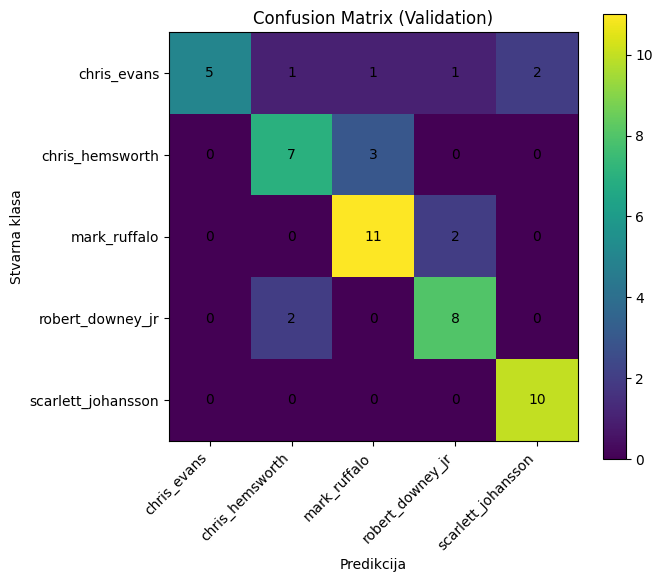

In [50]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt

# Reset generatora da bi predikcije krenule od prve slike (bitno!)
val_gen2.reset()

# MODEL.predict daje verovatnoće po klasama (softmax izlaz)
y_prob = model_m2.predict(val_gen2, verbose=0)

# Najveća verovatnoća => predikovana klasa
y_pred = np.argmax(y_prob, axis=1)

# Prave klase generator već zna (labeli po redosledu slika)
y_true = val_gen2.classes

# Nazivi klasa iz foldera (npr. chris_evans, mark_ruffalo, ...)
class_names = list(val_gen2.class_indices.keys())

print("Classification report (precision/recall/f1):\n")
print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion matrix: red = stvarna klasa, kolona = predikovana klasa
cm = confusion_matrix(y_true, y_pred)

print("Confusion matrix (broj tačnih/pogrešnih po klasama):\n")
print(cm)

# Vizuelni prikaz confusion matrix
plt.figure(figsize=(7,6))
plt.imshow(cm)
plt.title("Confusion Matrix (Validation)")
plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
plt.yticks(range(len(class_names)), class_names)
plt.colorbar()
plt.xlabel("Predikcija")
plt.ylabel("Stvarna klasa")

# Ispis brojeva u ćelijama matrice radi lakše interpretacije
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()


**Analiza po klasama**

Redosled klasa u matrici konfuzije: Chris Evans, Chris Hemsworth, Mark Ruffalo, Robert Downey Jr, Scarlett Johansson (redovi su stvarne, a kolone predviđene klase).

**1. Scarlett Johansson** (precision 0.83, recall 1.00, f1 0.91)
* Najbolje prepoznata klasa: **svih 10 slika** je tačno klasifikovano.
* Preciznost je nešto niža (0.83), jer je model dve slike Chrisa Evansa pogrešno proglasio Scarlett Johansson.

**2. Robert Downey Jr** (precision 0.73, recall 0.80, f1 0.76)
* Tačno je klasifikovano 8 od 10 slika, a 2 su zamenjene za Chrisa Hemswortha.
* Ovo je **najveće poboljšanje** u odnosu na CNN od nule, kod koga je ova klasa bila najslabija (recall 0.50). Model sa ImageNet karakteristikama mnogo bolje prepoznaje ovu osobu.

**3. Mark Ruffalo** (precision 0.73, recall 0.85, f1 0.79)
* Tačno je klasifikovano 11 od 13 slika, a 2 su zamenjene za Roberta Downey Jr-a.
* Preciznost je 0.73, jer model u ovu klasu svrstava i 3 slike Chrisa Hemswortha i jednu sliku Chrisa Evansa.

**4. Chris Hemsworth** (precision 0.70, recall 0.70, f1 0.70)
* Tačno je klasifikovano 7 od 10 slika, a sve 3 greške idu u istom smeru: proglašene su **Markom Ruffalom**.
* U ovu klasu model pogrešno svrstava i 2 slike Roberta Downey Jr-a i jednu Chrisa Evansa.

**5. Chris Evans** (precision 1.00, recall 0.50, f1 0.67)
* **Najproblematičnija klasa**: tačno je prepoznata samo polovina slika (5 od 10).
* Preciznost je savršena (1.00): kad god model kaže „Chris Evans”, u pravu je. Ali model ovu klasu predviđa retko i oprezno, pa propušta polovinu njegovih slika.
* Greške su raspršene na **sve četiri** ostale klase (1 Hemsworth, 1 Ruffalo, 1 Downey Jr, 2 Scarlett Johansson). Model, dakle, nije naučio karakteristike koje pouzdano izdvajaju ovu osobu.

**Globalne metrike**
* Ukupna tačnost: 0.77 (41 od 53 slike).
* Macro avg F1: 0.76, a weighted avg F1: 0.77. Klase su skoro izbalansirane, pa je razlika mala.

**Poređenje sa CNN-om od nule (recall po klasama)**

| Klasa | CNN od nule | MobileNetV2 |
|---|---|---|
| Chris Evans | 0.60 | 0.50 |
| Chris Hemsworth | 0.80 | 0.70 |
| Mark Ruffalo | 0.92 | 0.85 |
| Robert Downey Jr | 0.50 | **0.80** |
| Scarlett Johansson | 0.90 | **1.00** |

**Zaključak analize matrice**

Rezultati pokazuju da MobileNetV2 model:
* ima nešto višu ukupnu tačnost od CNN-a treniranog od nule (41 prema 40 tačnih slika) i ujednačenije rezultate po klasama (macro F1 0.76 prema 0.74),
* znatno bolje prepoznaje Roberta Downey Jr-a i Scarlett Johansson, ali nešto lošije Chrisa Evansa i Chrisa Hemswortha. Dva modela, dakle, **greše na različitim slikama**,
* i dalje ima poteškoće sa klasama sličnih vizuelnih karakteristika, a najviše sa Chrisom Evansom.

Model je dobra osnova za dalja unapređenja, poput:
* fine-tuning-a dela baznog modela,
* dodatne augmentacije podataka,
* ili upotrebe većeg i raznovrsnijeg skupa podataka.

In [51]:
import cv2
import random
import os
import numpy as np
import matplotlib.pyplot as plt

# Pomoćna funkcija za učitavanje i resize slike (za prikaz)
def load_img_rgb(path, img_size=(224,224)):
    img_bgr = cv2.imread(path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_rgb = cv2.resize(img_rgb, img_size)
    return img_rgb

# Priprema liste putanja slika iz validacionog generatora
val_paths = val_gen2.filepaths

# Predikcije već imamo: y_true, y_pred, class_names
# Nađi indekse tačnih i pogrešnih predikcija
correct_idxs = [i for i in range(len(y_true)) if y_pred[i] == y_true[i]]
wrong_idxs   = [i for i in range(len(y_true)) if y_pred[i] != y_true[i]]

print(f"Tačno klasifikovano: {len(correct_idxs)} / {len(y_true)}")
print(f"Pogrešno klasifikovano: {len(wrong_idxs)} / {len(y_true)}")


Tačno klasifikovano: 41 / 53
Pogrešno klasifikovano: 12 / 53


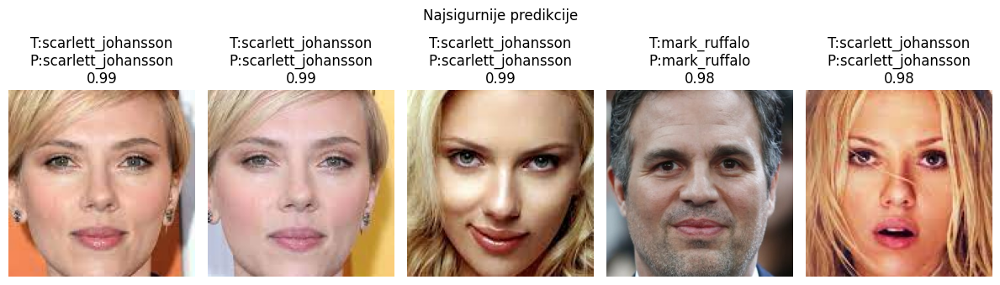

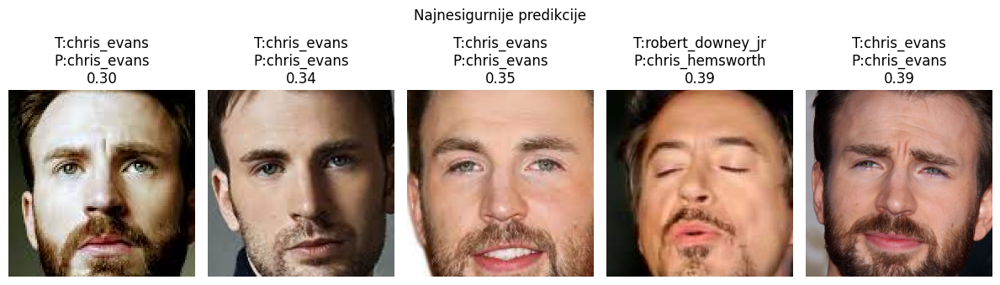

In [52]:
import os
import matplotlib.pyplot as plt

# confidence = max verovatnoća
conf = np.max(y_prob, axis=1)

# indeksi top 5 najviših i najnižih sigurnosti
best_idx = np.argsort(-conf)[:5]
worst_idx = np.argsort(conf)[:5]

def show_indices(indices, title):
    plt.figure(figsize=(12, 4))
    for i, idx in enumerate(indices):
        img_path = val_gen2.filepaths[idx]
        img = plt.imread(img_path)
        plt.subplot(1, len(indices), i+1)
        plt.imshow(img)
        true_name = class_names[y_true[idx]]
        pred_name = class_names[y_pred[idx]]
        plt.title(f"T:{true_name}\nP:{pred_name}\n{conf[idx]:.2f}")
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_indices(best_idx, "Najsigurnije predikcije")
show_indices(worst_idx, "Najnesigurnije predikcije")


## 4.6 Fine-tuning MobileNetV2

Fine-tuning znači da, pored „glave”, sada treniramo i deo unapred istrenirane MobileNetV2 baze. Tako model može da prilagodi visoko-nivo karakteristike (npr. delove lica) baš našem skupu Avengers slika. Learning rate se drastično smanjuje (1e-5), jer ne želimo velike promene težina koje bi „pokvarile” znanje preneto sa ImageNet-a.

**BatchNormalization slojeve ostavljamo zamrznute.** Oni čuvaju statistike (prosek i varijansu) naučene na milionima ImageNet slika. Ako bi se ažurirali na našim malim batch-evima od 16 slika, te statistike bi se pokvarile i tačnost bi pala.

In [53]:
# =========================
# Fine-tuning MobileNetV2
# =========================
# Ideja:
# 1) Prvo smo trenirali samo "glavu" (Dense sloj) dok je baza bila zamrznuta.
# 2) Sada "odmrzavamo" poslednjih 20 slojeva baze da se fino prilagode našem dataset-u.

base_model.trainable = True

# Od kog sloja kreće treniranje (poslednjih 20 slojeva);
# sve pre toga ostaje zamrznuto da ne "pokvarimo" opšte ImageNet karakteristike.
fine_tune_at = len(base_model.layers) - 20

for i, layer in enumerate(base_model.layers):
    # - slojevi pre fine_tune_at ostaju zamrznuti
    # - BatchNormalization slojevi ostaju zamrznuti UVEK: čuvaju statistike naučene na ImageNet-u,
    #   koje bi se na našim malim batch-evima (16 slika) pokvarile
    layer.trainable = (i >= fine_tune_at) and not isinstance(layer, tf.keras.layers.BatchNormalization)

print("Broj trainable slojeva u bazi:", sum(l.trainable for l in base_model.layers))

# OBAVEZNO: ponovo kompajliramo model posle promene trainable parametara.
# Learning rate je mali (1e-5), da samo fino podesimo težine, a ne da pokvarimo naučeno.
model_m2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Treniramo još najviše 10 epoha, sa NOVIM callback-ovima
history_ft = model_m2.fit(
    train_gen2,
    validation_data=val_gen2,
    epochs=10,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6),
    ]
)

val_loss_ft, val_acc_ft = model_m2.evaluate(val_gen2, verbose=0)
print(f"Posle fine-tuning-a: val_accuracy = {val_acc_ft:.4f}, val_loss = {val_loss_ft:.4f}")

Broj trainable slojeva u bazi: 13
Epoch 1/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step - accuracy: 0.9729 - loss: 0.1633 - val_accuracy: 0.6604 - val_loss: 0.8264 - learning_rate: 1.0000e-05
Epoch 2/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.9910 - loss: 0.0974 - val_accuracy: 0.7736 - val_loss: 0.7326 - learning_rate: 1.0000e-05
Epoch 3/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.9955 - loss: 0.0719 - val_accuracy: 0.7547 - val_loss: 0.7255 - learning_rate: 1.0000e-05
Epoch 4/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.9955 - loss: 0.0600 - val_accuracy: 0.7925 - val_loss: 0.7167 - learning_rate: 1.0000e-05
Epoch 5/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.9910 - loss: 0.0693 - val_accuracy: 0.7925 - val_loss: 0.6550 - learning_rate: 1.0000e-05
Epoch 6/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.9819 - loss: 0.0556 - val_accuracy: 0.7358 - val_loss: 0.7503 - learning_rate: 1.0000e-05
Epoch 7/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 18s 

### **Analiza fine-tuning rezultata (MobileNetV2 – poslednjih 20 slojeva)**

U ovoj fazi izvršen je fine-tuning MobileNetV2 modela: odmrznuto je poslednjih 20 slojeva bazne mreže, osim BatchNormalization slojeva, pa se u bazi trenira **13 slojeva**. Ostali slojevi su ostali zamrznuti. Cilj je bio da se karakteristike koje je mreža naučila na ImageNet-u dodatno prilagode licima Avengers likova. Learning rate je smanjen na 1e-5, kako bi promene težina bile male i postepene.

**Posmatranje treninga**
* Model je u fine-tuning ušao već dobro istreniran, pa je trening tačnost od početka visoka (oko 97%) i brzo dostiže skoro 100%.
* Trening loss se stalno smanjuje (sa 0.16 na 0.03).

**Posmatranje validacije**
* Validacioni loss u prvih nekoliko epoha **opada** (0.83 → 0.73 → 0.66) i dostiže minimum u **7. epohi**: val_loss = **0.5809**, val_accuracy = **0.8302**.
* Validaciona tačnost raste sa 0.66 na **0.83**, uz oscilacije koje su posledica malog validacionog skupa.
* Posle 7. epohe validacioni loss blago raste (0.66 → 0.70), dok trening loss i dalje pada, što je početak overfitting-a. Zahvaljujući `restore_best_weights=True`, model je vraćen na težine iz 7. epohe.

**Zaključak fine-tuning eksperimenta**

Fine-tuning je **poboljšao** model:

| Model | Val_accuracy | Tačno klasifikovano | Val_loss |
|---|---|---|---|
| CNN od nule | 0.7547 | 40 / 53 | 0.7617 |
| MobileNetV2 (zamrznuta baza) | 0.7736 | 41 / 53 | 0.7351 |
| **MobileNetV2 + fine-tuning** | **0.8302** | **44 / 53** | **0.5809** |

Prilagođavanjem poslednjih slojeva baze model je naučio karakteristike specifičnije za razlikovanje lica, pa je validacioni loss znatno niži, a tačnost najviša od sva tri modela.

Za ovaj rezultat bila su ključna dva detalja:
* **zamrznuti BatchNormalization slojevi**: statistike naučene na milionima ImageNet slika ostaju sačuvane, umesto da se kvare na batch-evima od samo 16 slika;
* **nov EarlyStopping i ReduceLROnPlateau** za svako treniranje, kako callback-ovi ne bi „pamtili” rezultat prethodnog modela.


 Razlika između modela je i dalje mala: od 40 do 44 tačne slike na 53. Uz to, najbolju epohu birali smo na osnovu istog validacionog skupa na kome merimo tačnost, pa je rezultat od 83% blago optimističan. Pouzdanija procena zahtevala bi poseban **test skup**, koji se ne koristi ni za treniranje ni za izbor epohe, kao i ponavljanje eksperimenta više puta.

# **Zajednički zaključak poređenja**

| Model                     | Pristup                                  | Val_accuracy           | Val_loss   | Prednosti                                                                                  | Nedostaci                                                                 |
| ------------------------- | ---------------------------------------- | ---------------------- | ---------- | ------------------------------------------------------------------------------------------ | ------------------------------------------------------------------------- |
| CNN (od nule)             | Klasični CNN                             | ≈ 0.75 (40/53)         | ≈ 0.76     | Jednostavna arhitektura, ne zahteva pretrenirani model                                     | Preko 11 miliona parametara, izražen overfitting (val_loss raste posle 9. epohe) |
| MobileNetV2               | Transfer learning (zamrznuta baza)       | ≈ 0.77 (41/53)         | ≈ 0.74     | Stabilan trening, bez izraženog overfitting-a, trenira se samo ~6 hiljada parametara       | Tačnost slična CNN-u; ImageNet karakteristike nisu specijalizovane za lica |
| MobileNetV2 + fine-tuning | Transfer learning + poslednjih 20 slojeva | **≈ 0.83 (44/53)**     | **≈ 0.58** | Najbolja tačnost i najmanji loss; karakteristike baze prilagođene licima                   | Duže treniranje; osetljiv na podešavanja (mali learning rate, zamrznuti BatchNormalization slojevi) |

Na osnovu dobijenih rezultata može se zaključiti da je **transfer learning sa fine-tuning-om dao najbolje rezultate**: validaciona tačnost je oko 83% (44 od 53 slike), a validacioni loss najmanji (0.58).

**CNN treniran od nule** postigao je solidnu tačnost od oko 75%, što pokazuje da i jednostavna mreža može da nauči da razlikuje osobe na malom skupu podataka. Ipak, sa preko 11 miliona parametara i samo 221 trening slikom, model brzo počinje da „pamti” trening slike, pa validacioni loss posle 9. epohe raste. To je izražen overfitting.

**MobileNetV2 sa zamrznutom bazom** dostigao je sličnu tačnost (oko 77%), ali uz mnogo stabilnije učenje: trenira se samo oko 6 hiljada parametara, a validacioni loss ravnomerno opada i ne raste. Znanje preneto sa ImageNet skupa daje dobre opšte karakteristike slike (ivice, teksture, oblike), ali one nisu specijalizovane za razlikovanje lica, pa tačnost nije značajno viša od CNN-a.

**Fine-tuning** je rešio upravo taj problem. Odmrzavanjem poslednjih slojeva baze, uz mali learning rate i zamrznute BatchNormalization slojeve, opšte ImageNet karakteristike su se prilagodile licima, pa je model postigao najbolju tačnost i najmanji loss.

**Važne pouke ovog eksperimenta:**
* **Detalji implementacije mogu da promene zaključak.** U prošlogodišnjoj verziji sveske callback-ovi su se delili između modela, a BatchNormalization slojevi nisu bili zamrznuti. Zbog toga je zaključak bio suprotan: da je CNN od nule najbolji, a da fine-tuning ne pomaže.
* **Mali skup podataka znači nesigurne rezultate.** Razlika između najslabijeg i najboljeg modela je samo 4 slike od 53. Pri ponovnom pokretanju brojevi se mogu promeniti za nekoliko procenata, a pouzdaniji zaključak zahtevao bi poseban test skup i više ponovljenih eksperimenata.
* **Složeniji model nije automatski bolji**, ali pretrenirani model, pažljivo prilagođen konkretnom problemu, obično daje najbolje rezultate kada podataka ima malo.

### **Implikacije za realni svet**

U realnim sistemima za prepoznavanje lica izbor modela zavisi od konteksta primene:
* **Mali, kontrolisani sistemi**
(npr. mala baza zaposlenih, studentski projekti, demo aplikacije)
→ I ovde je transfer learning najčešće najbolji izbor, jer pretrenirani model dobro radi i sa malo slika po osobi, kao što je pokazao i ovaj case study. Jednostavan CNN od nule može biti dovoljan za demonstraciju, ali je skloniji overfitting-u.
* **Veliki i dinamični sistemi**
(video nadzor, sistemi bezbednosti, javne aplikacije)
→ Transfer learning modeli imaju jasnu prednost zbog bolje generalizacije i otpornosti na promene osvetljenja, poze i okruženja. U praksi se koriste i specijalizovani modeli trenirani baš na milionima lica (npr. FaceNet, ArcFace), koji uče da izračunaju „otisak” lica, pa mogu da prepoznaju i nove osobe bez ponovnog treniranja.
* **Uređaji sa ograničenim resursima**
(mobilni telefoni, kamere, embedded sistemi)
→ Lagani modeli poput MobileNetV2 i MediaPipe detektora su projektovani upravo za brz rad na takvim uređajima.
